# Prompt Compression Masterclass
## Input Token Compression with LLMLingua-2 & Selective Context

> **What is prompt compression?** It is a technique to reduce the number of **input tokens** sent to an LLM, without meaningfully degrading the quality of the LLM's response. It does **not** compress output tokens — those are controlled separately via `max_tokens` and response formatting.

### Why it matters

LLM API pricing is split into **input** and **output** costs. In most production workloads (RAG pipelines, chat history, document QA), **60–80% of tokens are input**. Prompt compression targets this dominant cost driver.

```
┌─────────────────────────────────────────────────────────────┐
│                    LLM API Call Flow                        │
│                                                             │
│  [System Prompt] + [Context/Docs] + [Question]  ──► LLM    │
│        ↑                  ↑              ↑           │      │
│     untouched         COMPRESSED      untouched      │      │
│                                                      ▼      │
│                                              [LLM Response] │
│                                               (not changed) │
└─────────────────────────────────────────────────────────────┘
```

### Where compression has the biggest impact

| Scenario | Typical Input Size | Compression Savings | Why |
|----------|-------------------|--------------------:|-----|
| **RAG with 5+ retrieved chunks** | 3,000–15,000 tokens | **40–70%** | Retrieved docs contain massive redundancy |
| **Multi-turn chat (10+ turns)** | 2,000–8,000 tokens | **30–50%** | Older turns have repetitive context |
| **Long document QA** | 5,000–50,000 tokens | **50–75%** | Reports/papers have filler text |
| **Few-shot prompts (5+ examples)** | 500–3,000 tokens | **30–50%** | Example text is verbose |
| **Code context** | 1,000–5,000 tokens | **20–40%** | Lower — syntax tokens are essential |
| **Short single-turn query** | 50–200 tokens | **~0%** | Not worth compressing |

**Rule of thumb:** If your input is under ~500 tokens, skip compression — the overhead isn't worth it. Compression shines when inputs are **1,000+ tokens**.

---

### Table of Contents

| # | Section | What You'll Learn |
|---|---------|-------------------|
| 0 | Setup & Configuration | Install dependencies, configure Cisco internal API, set pricing |
| 1 | Token & Cost Tracker | Reusable utility that measures every experiment |
| 2 | Selective Context | Entropy-based compression — how GPT-2 self-information filters tokens |
| 3 | LLMLingua-2 | Learned compression — BERT classifies each token as keep/discard |
| 4 | RAG Pipeline | **Highest ROI** — compress retrieved documents before LLM call |
| 5 | Multi-turn Chat | Compress conversation history to fit context windows |
| 6 | Long Document QA | Fit large documents into smaller windows (40% and 25% retention) |
| 7 | Few-Shot Prompts | Compress examples while preserving label mappings |
| 8 | Code Summarization | Compress code context with syntax-aware `force_tokens` |
| 9 | Benchmark | Head-to-head comparison table across all experiments |
| 10 | Cost Dashboard | Charts, cumulative savings, and production scale projections |
| 11 | Where Compression Helps Most | Impact ranking and when NOT to compress |
| **12** | **Production Guide** | **Can LLMLingua-2 run in production? Architecture, concerns, solutions** |
| **13** | **Production Utility Class** | **`PromptCompressionService` — drop-in module for any project** |
| **14** | **REST API** | **FastAPI server exposing compression as HTTP endpoints** |

---

## 0. Setup & Configuration

Run the install cell below **once** to set up all dependencies. This notebook uses:

| Component | Purpose |
|-----------|---------|
| `selective-context` | GPT-2 based entropy compression |
| `llmlingua` | Microsoft's learned token classifier (LLMLingua-2) |
| `tiktoken` | Fast token counting for cost tracking |
| `openai` | Azure OpenAI client for Cisco internal API |
| `transformers` + `torch` | Model backends for compression |
| `spacy` | NLP pipeline for Selective Context |

In [7]:
import sys
print(sys.version)
print(sys.executable)

3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 17.0.0 (clang-1700.6.3.2)]
/Users/vaibkum3/Desktop/Learnings/.venv/bin/python


In [ ]:
# INSTALL ALL DEPENDENCIES (run once)
import sys

# selective-context has a pinned spacy==3.2.0 dep — install without deps, then add modern versions
!{sys.executable} -m pip install selective-context --no-deps
!{sys.executable} -m pip install spacy transformers torch nltk
!{sys.executable} -m spacy download en_core_web_sm

# LLM providers, compression, and utilities
!{sys.executable} -m pip install -q llmlingua openai tiktoken matplotlib pandas tabulate python-dotenv

print("All packages installed!")


[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.1 MB/s  0:00:00eta 0:00:01

[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')

[notice] A new release of pip is available: 26.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
All packages installed!
For LOCAL execution: install Ollama (brew install ollama) and pull a model.


### 0.1 Model & Pricing Config

Select the deployment model and configure per-token pricing. All calls go through the **Cisco internal Azure OpenAI endpoint** — no external API keys needed, just OAuth client credentials in `.env`.

In [27]:
import os, time

# ============================================================
# PRICING CONFIG (USD per 1M tokens)
# ============================================================
PRICING = {
    # Cisco Internal Azure OpenAI deployments
    "gpt-4.1":          {"input": 2.00,  "output": 8.00},
    "gpt-4o":            {"input": 2.50,  "output": 10.00},
    "gpt-4o-mini":       {"input": 0.15,  "output": 0.60},
    "gpt-4-turbo":       {"input": 10.00, "output": 30.00},
    "gpt-3.5-turbo":     {"input": 0.50,  "output": 1.50},
}

# ============================================================
# CHOOSE YOUR MODEL (Cisco internal deployment name)
# ============================================================
LLM_MODEL = "gpt-4.1"

print(f"Model:  {LLM_MODEL}")
print(f"  Input:  ${PRICING[LLM_MODEL]['input']:.2f} / 1M tokens")
print(f"  Output: ${PRICING[LLM_MODEL]['output']:.2f} / 1M tokens")
print("  ** Cisco internal Azure OpenAI endpoint **")

Model:  gpt-4.1
  Input:  $2.00 / 1M tokens
  Output: $8.00 / 1M tokens
  ** Cisco internal Azure OpenAI endpoint **


---
## 1. Token & Cost Tracker

Every experiment in this notebook is tracked by `CostTracker`. For each run it records:

| Metric | Description |
|--------|-------------|
| **Original tokens** | Input tokens *before* compression |
| **Compressed tokens** | Input tokens *after* compression |
| **Output tokens** | Tokens the LLM generated (unaffected by compression) |
| **Compression ratio** | Original ÷ Compressed (e.g., 2.5x = 60% reduction) |
| **Cost (original vs compressed)** | Dollar cost difference using the pricing table |
| **Savings %** | How much cheaper the compressed call was |

> **Key insight:** Because compression only reduces **input** tokens, savings scale with the input pricing rate. Models with expensive input pricing (like GPT-4 Turbo at $10/1M) benefit more from compression than cheap models.

In [57]:
import tiktoken
import pandas as pd
from dataclasses import dataclass
from IPython.display import display, HTML


def count_tokens(text: str, model: str = "gpt-4o") -> int:
    """Count tokens using tiktoken."""
    try:
        enc = tiktoken.encoding_for_model(model)
    except KeyError:
        enc = tiktoken.get_encoding("cl100k_base")
    return len(enc.encode(text))


@dataclass
class ExperimentResult:
    name: str
    method: str
    original_tokens: int
    compressed_tokens: int
    output_tokens: int
    compression_ratio: float
    original_cost: float
    compressed_cost: float
    savings: float
    savings_pct: float
    compression_time_ms: float
    llm_response: str = ""


class CostTracker:
    def __init__(self, model: str, pricing: dict):
        self.model = model
        self.price_in = pricing[model]["input"]
        self.price_out = pricing[model]["output"]
        self.results: list = []

    def cost(self, input_tokens: int, output_tokens: int) -> float:
        return (input_tokens * self.price_in + output_tokens * self.price_out) / 1_000_000

    def log(self, name, method, original_text, compressed_text,
            output_tokens, compression_time_ms, llm_response=""):
        orig_tok = count_tokens(original_text, self.model)
        comp_tok = count_tokens(compressed_text, self.model)
        ratio = orig_tok / max(comp_tok, 1)
        orig_cost = self.cost(orig_tok, output_tokens)
        comp_cost = self.cost(comp_tok, output_tokens)
        savings = orig_cost - comp_cost
        savings_pct = (savings / orig_cost * 100) if orig_cost > 0 else 0

        r = ExperimentResult(
            name=name, method=method,
            original_tokens=orig_tok, compressed_tokens=comp_tok,
            output_tokens=output_tokens, compression_ratio=round(ratio, 2),
            original_cost=orig_cost, compressed_cost=comp_cost,
            savings=savings, savings_pct=round(savings_pct, 1),
            compression_time_ms=round(compression_time_ms, 1),
            llm_response=llm_response,
        )
        self.results.append(r)
        self._show(r)
        return r

    def _show(self, r):
        clr = "#059669" if r.savings_pct > 20 else "#d97706" if r.savings_pct > 5 else "#6b7280"
        html = (
            '<div style="background:#ffffff;border:1px solid #e5e7eb;border-radius:10px;'
            'padding:16px;margin:8px 0;font-family:monospace;color:#1f2937;box-shadow:0 1px 3px rgba(0,0,0,0.1)">'
            f'<div style="font-size:14px;font-weight:700;margin-bottom:10px">'
            f'{r.name} <span style="color:#6b7280;font-weight:400">({r.method})</span></div>'
            '<table style="width:100%;border-collapse:collapse;font-size:12px">'
            f'<tr><td style="padding:4px 8px;color:#6b7280">Original tokens</td>'
            f'<td style="padding:4px 8px;font-weight:600;color:#1f2937">{r.original_tokens:,}</td>'
            f'<td style="padding:4px 8px;color:#6b7280">Compressed tokens</td>'
            f'<td style="padding:4px 8px;font-weight:600;color:#1f2937">{r.compressed_tokens:,}</td></tr>'
            f'<tr><td style="padding:4px 8px;color:#6b7280">Output tokens</td>'
            f'<td style="padding:4px 8px;font-weight:600;color:#1f2937">{r.output_tokens:,}</td>'
            f'<td style="padding:4px 8px;color:#6b7280">Compression ratio</td>'
            f'<td style="padding:4px 8px;font-weight:600;color:#1f2937">{r.compression_ratio:.1f}x</td></tr>'
            f'<tr><td style="padding:4px 8px;color:#6b7280">Cost (original)</td>'
            f'<td style="padding:4px 8px;color:#dc2626;font-weight:600">${r.original_cost:.6f}</td>'
            f'<td style="padding:4px 8px;color:#6b7280">Cost (compressed)</td>'
            f'<td style="padding:4px 8px;color:#059669;font-weight:600">${r.compressed_cost:.6f}</td></tr>'
            f'<tr><td style="padding:4px 8px;color:#6b7280">Comp time</td>'
            f'<td style="padding:4px 8px;font-weight:600;color:#1f2937">{r.compression_time_ms:.0f} ms</td>'
            f'<td style="padding:4px 8px;color:#6b7280">Savings</td>'
            f'<td style="padding:4px 8px;font-weight:700;font-size:14px;color:{clr}">'
            f'{r.savings_pct:.1f}% (${r.savings:.6f})</td></tr>'
            '</table></div>'
        )
        display(HTML(html))

    def summary_df(self) -> pd.DataFrame:
        return pd.DataFrame([vars(r) for r in self.results])

    def total_savings(self):
        df = self.summary_df()
        total_orig = df["original_cost"].sum()
        total_comp = df["compressed_cost"].sum()
        total_saved = df["savings"].sum()
        avg_ratio = df["compression_ratio"].mean()
        html = (
            '<div style="background:linear-gradient(135deg,#f8fafc,#eef2ff);border:1px solid #c7d2fe;'
            'border-radius:12px;padding:20px;margin:12px 0;font-family:monospace;color:#1f2937;box-shadow:0 2px 6px rgba(0,0,0,0.08)">'
            f'<div style="font-size:16px;font-weight:700;margin-bottom:14px;color:#111827">'
            f'Cumulative Cost Report ({len(self.results)} experiments)</div>'
            '<div style="display:flex;gap:20px;flex-wrap:wrap">'
            f'<div style="flex:1;min-width:120px;text-align:center">'
            f'<div style="font-size:22px;font-weight:700;color:#dc2626">${total_orig:.6f}</div>'
            f'<div style="font-size:10px;color:#6b7280;margin-top:4px">TOTAL ORIGINAL</div></div>'
            f'<div style="flex:1;min-width:120px;text-align:center">'
            f'<div style="font-size:22px;font-weight:700;color:#059669">${total_comp:.6f}</div>'
            f'<div style="font-size:10px;color:#6b7280;margin-top:4px">TOTAL COMPRESSED</div></div>'
            f'<div style="flex:1;min-width:120px;text-align:center">'
            f'<div style="font-size:22px;font-weight:700;color:#4f46e5">${total_saved:.6f}</div>'
            f'<div style="font-size:10px;color:#6b7280;margin-top:4px">TOTAL SAVED</div></div>'
            f'<div style="flex:1;min-width:120px;text-align:center">'
            f'<div style="font-size:22px;font-weight:700;color:#d97706">{avg_ratio:.1f}x</div>'
            f'<div style="font-size:10px;color:#6b7280;margin-top:4px">AVG COMPRESSION</div></div>'
            '</div></div>'
        )
        display(HTML(html))


def show_comparison(label, original_prompt, compressed_prompt, original_response, compressed_response):
    """Display a side-by-side comparison of original vs compressed prompts and responses."""
    orig_tok = count_tokens(original_prompt)
    comp_tok = count_tokens(compressed_prompt)
    reduction = (1 - comp_tok / orig_tok) * 100 if orig_tok > 0 else 0
    html = (
        '<div style="font-family:sans-serif;margin:12px 0">'
        f'<div style="font-size:15px;font-weight:700;margin-bottom:8px;color:#111827">{label}</div>'
        '<div style="display:flex;gap:12px;flex-wrap:wrap">'
        # Original prompt
        '<div style="flex:1;min-width:300px">'
        f'<div style="font-size:12px;font-weight:600;color:#dc2626;margin-bottom:4px">'
        f'ORIGINAL PROMPT ({orig_tok:,} tokens)</div>'
        '<div style="background:#fef2f2;border:1px solid #fecaca;border-radius:8px;'
        'padding:10px;font-size:11px;color:#1f2937;max-height:200px;overflow-y:auto;'
        f'white-space:pre-wrap;font-family:monospace">{original_prompt[:1500]}{"..." if len(original_prompt) > 1500 else ""}</div>'
        '</div>'
        # Compressed prompt
        '<div style="flex:1;min-width:300px">'
        f'<div style="font-size:12px;font-weight:600;color:#059669;margin-bottom:4px">'
        f'COMPRESSED PROMPT ({comp_tok:,} tokens — {reduction:.0f}% smaller)</div>'
        '<div style="background:#f0fdf4;border:1px solid #bbf7d0;border-radius:8px;'
        'padding:10px;font-size:11px;color:#1f2937;max-height:200px;overflow-y:auto;'
        f'white-space:pre-wrap;font-family:monospace">{compressed_prompt[:1500]}{"..." if len(compressed_prompt) > 1500 else ""}</div>'
        '</div></div>'
        # Responses
        '<div style="display:flex;gap:12px;flex-wrap:wrap;margin-top:8px">'
        '<div style="flex:1;min-width:300px">'
        '<div style="font-size:12px;font-weight:600;color:#dc2626;margin-bottom:4px">RESPONSE (original)</div>'
        '<div style="background:#fff;border:1px solid #e5e7eb;border-radius:8px;'
        'padding:10px;font-size:12px;color:#1f2937;max-height:250px;overflow-y:auto;'
        f'white-space:pre-wrap">{original_response}</div>'
        '</div>'
        '<div style="flex:1;min-width:300px">'
        '<div style="font-size:12px;font-weight:600;color:#059669;margin-bottom:4px">RESPONSE (compressed)</div>'
        '<div style="background:#fff;border:1px solid #e5e7eb;border-radius:8px;'
        'padding:10px;font-size:12px;color:#1f2937;max-height:250px;overflow-y:auto;'
        f'white-space:pre-wrap">{compressed_response}</div>'
        '</div></div></div>'
    )
    display(HTML(html))


tracker = CostTracker(model=LLM_MODEL, pricing=PRICING)
print(f"CostTracker ready - model: {LLM_MODEL}")


CostTracker ready - model: gpt-4.1


### 1.1 LLM Call Helper (Cisco Internal API)

The `call_llm()` function handles:
- **Auto-refreshing OAuth tokens** (expires every 3600s, refreshes at 3500s)
- **AzureOpenAI client** pointed at `https://chat-ai.cisco.com`
- Returns `(response_text, output_token_count)` for the tracker

Credentials are loaded from `.env` file (`CLIENT_ID`, `CLIENT_SECRET`, `APP_KEY`, `TOKEN_URL`).

In [29]:
import base64, os, time as _time
import requests
from dotenv import load_dotenv
from openai import AzureOpenAI

# ============================================================
# Cisco Internal Azure OpenAI — with auto-refreshing token
# ============================================================

load_dotenv()

_token_cache = {"access_token": None, "app_key": None, "expires_at": 0}
_azure_client = None

def _refresh_token():
    """Fetch a new OAuth token if expired or missing (TTL = 3600s, refresh at 3500s)."""
    global _azure_client
    now = _time.time()
    if _token_cache["access_token"] and now < _token_cache["expires_at"]:
        return  # still valid

    client_id = os.getenv("CLIENT_ID")
    client_secret = os.getenv("CLIENT_SECRET")
    app_key = os.getenv("APP_KEY")
    token_url = os.getenv("TOKEN_URL")

    creds = base64.b64encode(f"{client_id}:{client_secret}".encode()).decode()
    resp = requests.post(
        token_url,
        data="grant_type=client_credentials",
        headers={
            "Accept": "*/*",
            "Content-Type": "application/x-www-form-urlencoded",
            "Authorization": f"Basic {creds}",
        },
    )
    resp.raise_for_status()
    data = resp.json()

    _token_cache["access_token"] = data["access_token"]
    _token_cache["app_key"] = app_key
    # Refresh 100s before actual expiry to avoid edge-case failures
    _token_cache["expires_at"] = now + data.get("expires_in", 3600) - 100

    # Invalidate existing client so it picks up the new token
    _azure_client = None
    print(f"Token refreshed — valid for ~{data.get('expires_in', 3600) - 100}s")


def _get_azure_client():
    """Return an AzureOpenAI client, refreshing the token if needed."""
    global _azure_client
    _refresh_token()
    if _azure_client is None:
        _azure_client = AzureOpenAI(
            azure_endpoint="https://chat-ai.cisco.com",
            api_key=_token_cache["access_token"],
            api_version="2023-08-01-preview",
        )
    return _azure_client


# ---------- unified call ----------
def call_llm(prompt: str, system: str = "You are a helpful assistant.",
             model: str = LLM_MODEL, max_tokens: int = 300):
    """Call the Cisco internal Azure OpenAI API and return (response_text, output_token_count)."""
    client = _get_azure_client()

    resp = client.chat.completions.create(
        model=model,
        messages=[
            {"role": "system", "content": system},
            {"role": "user", "content": prompt},
        ],
        max_tokens=max_tokens,
        user=f'{{"appkey": "{_token_cache["app_key"]}"}}',
    )
    text = resp.choices[0].message.content
    out_tokens = resp.usage.completion_tokens
    return text, out_tokens


# Eager first fetch so we fail fast if creds are bad
_refresh_token()
print(f"LLM helper ready — Cisco internal API (model: {LLM_MODEL})")

DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): id.cisco.com:443
DEBUG:urllib3.connectionpool:https://id.cisco.com:443 "POST /oauth2/default/v1/token HTTP/1.1" 200 759


Token refreshed — valid for ~3500s
LLM helper ready — Cisco internal API (model: gpt-4.1)


---
## 2. Selective Context (Entropy-Based Input Compression)

**Algorithm:** Uses GPT-2 to compute the *self-information* (surprise) of each token. Tokens that are highly predictable from their left context carry little information and get filtered out. Only rare, informative tokens survive.

```
"The company reported a total consolidated revenue of $4.2 billion"
      ↓ GPT-2 self-information scoring ↓
"company reported total revenue $4.2 billion"
 (removed: "The", "a", "consolidated", "of" — predictable filler)
```

| Property | Detail |
|----------|--------|
| **What it compresses** | Input tokens only (context, documents, history) |
| **Backbone model** | GPT-2 (124M params, runs on CPU) |
| **Context direction** | Unidirectional (left-to-right only) |
| **Max safe compression** | ~2x (50% token reduction) |
| **Setup complexity** | Low — just GPT-2 + spaCy |
| **Best for** | Quick prototyping, moderate compression needs |

### Loading SSL certs & models

The cells below configure SSL (for corporate proxy) and load the local GPT-2 model for Selective Context.

In [ ]:
import os, ssl, certifi

# Combined PEM: system keychain (Cisco proxy certs) + certifi bundle
# To regenerate: security find-certificate -a -p /Library/Keychains/System.keychain > /tmp/system_certs.pem
#                cat /tmp/system_certs.pem $(python -m certifi) > final.pem
FINAL_PEM = os.path.join(os.getcwd(), "final.pem")
assert os.path.exists(FINAL_PEM), f"final.pem not found at {FINAL_PEM}"

os.environ["REQUESTS_CA_BUNDLE"] = FINAL_PEM
os.environ["SSL_CERT_FILE"] = FINAL_PEM
os.environ["CURL_CA_BUNDLE"] = FINAL_PEM
os.environ["HF_HUB_HTTP_TIMEOUT"] = "120"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"

# Suppress "unauthenticated requests" warning from HF Hub
# Get a free token at https://huggingface.co/settings/tokens (optional but recommended)
HF_TOKEN = os.environ.get("HF_TOKEN", "")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
else:
    os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

print(f"CA bundle: {FINAL_PEM}")
print(f"HF Token: {'set' if HF_TOKEN else 'not set (warning is harmless, downloads still work)'}")

CA bundle: /Users/vaibkum3/Desktop/Learnings/final.pem
HF Token: set


In [ ]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import os

LOCAL_GPT2 = os.path.expanduser("./models/gpt2")
tokenizer = GPT2Tokenizer.from_pretrained(LOCAL_GPT2)
model = GPT2LMHeadModel.from_pretrained(LOCAL_GPT2)
del model, tokenizer
print("GPT-2 loaded from local folder")

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 9938.79it/s]

GPT-2 loaded from local folder


In [5]:
from selective_context import SelectiveContext

# NOTE: model_type must be 'gpt2' (not 'gpt2-medium').
# The package only supports 'gpt2' or 'curie' as model_type values.
# Using anything else leaves get_self_information unimplemented -> NotImplementedError.
sc = SelectiveContext(model_type='gpt2', lang='en')
print("Selective Context loaded (GPT-2 backbone)")

Loading dependencies...
Using device: cpu


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 22282.10it/s]

model loaded
Selective Context loaded (GPT-2 backbone)


### 2.1 Demo: Compression at Multiple Ratios

We compress the same financial report at three levels: 30%, 50%, and 70% token reduction.

**What to watch for:**
- At 30% reduction: mostly filler words removed, meaning fully preserved
- At 50% reduction: some detail lost, but key facts survive
- At 70% reduction: aggressive — some important context may disappear

> **Remember:** `reduce_ratio=0.5` means *remove 50%* of tokens (keep 50%).

In [55]:
# SAMPLE TEXT - used throughout the notebook
sample_text = """The quarterly financial performance report for the third quarter of fiscal year 2024
indicates that the company's consolidated total revenue increased quite significantly by approximately
23 percent when compared to the exact same corresponding quarter in the immediately preceding fiscal
year, ultimately reaching a grand total of $4.2 billion in consolidated revenue across all of its
various business segments and geographical operating regions worldwide. The Chief Executive Officer
noted during the quarterly earnings conference call that this impressive growth trajectory was primarily
driven by the exceptionally strong performance exhibited by the cloud computing services division and
the newly launched artificial intelligence product line, both of which exceeded their internal
performance targets by a considerable margin."""

print("SELECTIVE CONTEXT - Multi-ratio compression")
print("=" * 60)

for ratio in [0.7, 0.5, 0.3]:
    t0 = time.time()
    compressed, removed = sc(sample_text, reduce_ratio=ratio)
    elapsed = (time.time() - t0) * 1000

    orig_tok = count_tokens(sample_text)
    comp_tok = count_tokens(compressed)

    print(f"\nTarget reduction: {int((1-ratio)*100)}% | Actual: {int((1 - comp_tok/orig_tok)*100)}%")
    print(f"Tokens: {orig_tok} -> {comp_tok} | Time: {elapsed:.0f}ms")
    print(f"Output: {compressed.strip()[:200]}...")


SELECTIVE CONTEXT - Multi-ratio compression

Target reduction: 30% | Actual: 70%
Tokens: 136 -> 40 | Time: 901ms
Output: The quarterly financial performance report 2024 indicates quite when the exact same corresponding quarter ultimately across geographical operating regions worldwide The Chief Executive Officer noted d...

Target reduction: 50% | Actual: 41%
Tokens: 136 -> 80 | Time: 100ms
Output: The quarterly financial performance report 2024 indicates the company's consolidated total revenue quite by approximately 23 percent when the exact same corresponding quarter the immediately preceding...

Target reduction: 70% | Actual: 24%
Tokens: 136 -> 103 | Time: 111ms
Output: The quarterly financial performance report 2024 indicates the company's consolidated total revenue increased quite significantly by approximately 23 percent when the exact same corresponding quarter i...


### 2.2 Selective Context + LLM Call (Tracked)

Now we use Selective Context in a real pipeline: compress the report, then ask the LLM a question about it.

**Critical pattern — only compress the context, never the question:**
```python
# CORRECT — compress context, keep question intact
compressed_ctx = sc(document, reduce_ratio=0.5)
prompt = f"Report: {compressed_ctx}\n\nQuestion: {question}\nAnswer:"

# WRONG — compressing the question loses what we're asking
compressed_all = sc(full_prompt, reduce_ratio=0.5)  # Don't do this!
```

The tracker logs the token difference and cost savings.

In [58]:
question = "What drove the company's revenue growth in Q3 2024?"

full_context = f"""Based on the following report, answer the question.

Report:
{sample_text}

Question: {question}
Answer:"""

# --- Baseline (no compression) ---
resp_orig, out_orig = call_llm(full_context)

# --- Compress the context portion only ---
t0 = time.time()
compressed_ctx, _ = sc(sample_text, reduce_ratio=0.5)
comp_time = (time.time() - t0) * 1000

compressed_prompt = f"""Based on the following report, answer the question.

Report:
{compressed_ctx}

Question: {question}
Answer:"""

response, out_tokens = call_llm(compressed_prompt)

tracker.log(
    name="Selective Context - Q3 Report QA",
    method="selective_context",
    original_text=full_context,
    compressed_text=compressed_prompt,
    output_tokens=out_tokens,
    compression_time_ms=comp_time,
    llm_response=response,
)

show_comparison("Selective Context — Q3 Report QA",
                full_context, compressed_prompt,
                resp_orig, response)

INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,165,Compressed tokens,110
Output tokens,42,Compression ratio,1.5x
Cost (original),$0.000666,Cost (compressed),$0.000556
Comp time,157 ms,Savings,16.5% ($0.000110)


---
## 3. LLMLingua-2 (Learned Input Token Compression)

**Algorithm:** An XLM-RoBERTa model (fine-tuned via GPT-4 data distillation) classifies each token as **KEEP** or **DISCARD**. Unlike Selective Context, it uses **bidirectional** context — it sees the full sentence before deciding which tokens matter.

```
"The quarterly financial performance report for the third quarter of fiscal year 2024
 indicates that the company's consolidated total revenue increased significantly"
      ↓ XLM-RoBERTa binary classification ↓
"quarterly financial report third quarter fiscal 2024 company's revenue increased significantly"
```

| Property | Detail |
|----------|--------|
| **What it compresses** | Input tokens only (same as Selective Context) |
| **Backbone model** | XLM-RoBERTa-Large (~1.2GB) |
| **Context direction** | Bidirectional (sees full sentence) |
| **Max safe compression** | ~5x (80% token reduction) |
| **Speed** | 3–6x faster than LLMLingua v1 |
| **Key feature** | `force_tokens` — protect specific characters from removal |
| **Best for** | Production use, high compression, RAG pipelines |

### Why LLMLingua-2 > Selective Context for production

1. **Bidirectional** — sees surrounding context, makes smarter keep/discard decisions
2. **Higher compression** — safely handles 3–5x vs Selective Context's ~2x ceiling
3. **Question-aware** — can take the user's question as input to prioritize relevant tokens
4. **`force_tokens`** — lets you protect syntax (`()=:`) for code, or punctuation (`.?!`) for text

In [17]:
import os, subprocess, json, urllib.request

def download_hf_model(repo_id: str, local_dir: str = None, 
                      file_extensions: tuple = (".json", ".txt", ".safetensors", ".bin", ".model", ".vocab")):
    """Download any HuggingFace model via curl (bypasses Python proxy issues).
    
    Args:
        repo_id: HuggingFace repo (e.g. 'gpt2', 'microsoft/llmlingua-2-xlm-roberta-large-meetingbank')
        local_dir: Where to save. Defaults to ./models/{repo_name}
        file_extensions: Only download files matching these extensions
    
    Returns:
        str: Path to the local model directory (use with from_pretrained())
    """
    repo_name = repo_id.split("/")[-1]
    local_dir = local_dir or os.path.join(os.getcwd(), "models", repo_name)
    os.makedirs(local_dir, exist_ok=True)

    # Get file list from HF API
    api_url = f"https://huggingface.co/api/models/{repo_id}/tree/main"
    print(f"Fetching file list from {repo_id}...")
    try:
        req = urllib.request.Request(api_url, headers={"User-Agent": "python"})
        with urllib.request.urlopen(req, timeout=30) as resp:
            files_info = json.loads(resp.read().decode())
    except Exception as e:
        raise RuntimeError(f"Failed to fetch file list: {e}\nCheck your network or pass files manually.")

    # Filter to relevant model files (skip .gitattributes, README, etc.)
    files = [
        f for f in files_info 
        if f["type"] == "file" and any(f["path"].endswith(ext) for ext in file_extensions)
    ]

    print(f"Found {len(files)} files to download -> {local_dir}\n")
    base_url = f"https://huggingface.co/{repo_id}/resolve/main"

    for i, f in enumerate(files, 1):
        fname = f["path"]
        size_mb = f.get("size", 0) / 1e6
        dest = os.path.join(local_dir, fname)

        if os.path.exists(dest) and os.path.getsize(dest) == f.get("size", -1):
            print(f"  [{i}/{len(files)}] ✓ {fname} ({size_mb:.1f} MB) — cached")
            continue

        print(f"  [{i}/{len(files)}] ↓ {fname} ({size_mb:.1f} MB)...")
        os.makedirs(os.path.dirname(dest) or local_dir, exist_ok=True)
        result = subprocess.run(
            ["curl", "-L", "--progress-bar", "-o", dest, f"{base_url}/{fname}"],
            capture_output=False,
        )
        if result.returncode != 0 or not os.path.exists(dest):
            raise RuntimeError(f"curl failed for {fname}")
        print(f"           ✓ done")

    print(f"\n✓ {repo_id} ready at {local_dir}")
    return local_dir

In [20]:
llmlingua_path = download_hf_model("microsoft/llmlingua-2-xlm-roberta-large-meetingbank")


Fetching file list from microsoft/llmlingua-2-xlm-roberta-large-meetingbank...
Found 5 files to download -> /Users/vaibkum3/Desktop/Learnings/models/llmlingua-2-xlm-roberta-large-meetingbank

  [1/5] ✓ config.json (0.0 MB) — cached
  [2/5] ✓ model.safetensors (2235.8 MB) — cached
  [3/5] ✓ special_tokens_map.json (0.0 MB) — cached
  [4/5] ✓ tokenizer.json (17.1 MB) — cached
  [5/5] ✓ tokenizer_config.json (0.0 MB) — cached

✓ microsoft/llmlingua-2-xlm-roberta-large-meetingbank ready at /Users/vaibkum3/Desktop/Learnings/models/llmlingua-2-xlm-roberta-large-meetingbank


In [ ]:
from llmlingua import PromptCompressor
llm_lingua = PromptCompressor(
    model_name=llmlingua_path,
    use_llmlingua2=True,
    device_map="gpu",   # change to "cuda" for GPU
)

print("LLMLingua-2 loaded (XLM-RoBERTa backbone)")


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 7078.43it/s]

LLMLingua-2 loaded (XLM-RoBERTa backbone)


### 3.1 Demo: Compression at Multiple Ratios

Same text, three retention levels: 70%, 50%, 30%.

> **Note:** `rate=0.5` in LLMLingua-2 means *keep 50%* of tokens (opposite convention to Selective Context's `reduce_ratio`).

In [59]:
print("LLMLINGUA-2 - Multi-ratio compression")
print("=" * 60)

for rate in [0.7, 0.5, 0.3]:
    t0 = time.time()
    result = llm_lingua.compress_prompt(
        sample_text,
        rate=rate,
        force_tokens=["\n", ".", "!", "?"],
    )
    elapsed = (time.time() - t0) * 1000

    print(f"\nTarget keep: {int(rate*100)}% | {result['origin_tokens']} -> {result['compressed_tokens']} tokens")
    print(f"Ratio: {float(str(result['ratio']).rstrip('x')):.2f}x | Time: {elapsed:.0f}ms")
    print(f"Output: {result['compressed_prompt'].strip()[:200]}...")

LLMLINGUA-2 - Multi-ratio compression

Target keep: 70% | 137 -> 95 tokens
Ratio: 1.40x | Time: 2375ms
Output: quarterly financial performance report for third quarter of fiscal year 2024
 indicates company's consolidated total revenue increased significantly by approximately
 23 percent compared to same corre...

Target keep: 50% | 137 -> 71 tokens
Ratio: 1.90x | Time: 422ms
Output: quarterly financial performance report third quarter fiscal year 2024
 indicates company's consolidated revenue increased
 23 percent compared quarter preceding fiscal
 year reaching $4. 2 billion con...

Target keep: 30% | 137 -> 48 tokens
Ratio: 2.90x | Time: 392ms
Output: quarterly report third quarter 2024
 consolidated revenue increased
 23 percent
 $4. 2 billion
 business segments regions. Chief Executive Officer
 growth
 driven cloud computing services division
 ar...


### 3.2 LLMLingua-2 + LLM Call (Tracked)

Same Q&A task as Section 2.2, but using LLMLingua-2. Notice the `question` parameter — this makes compression **question-aware**, prioritizing tokens relevant to what's being asked.

In [60]:
t0 = time.time()
result = llm_lingua.compress_prompt(
    sample_text,
    question=question,
    rate=0.5,
    force_tokens=["\n", ".", "!", "?"],
)
comp_time = (time.time() - t0) * 1000

ll2_prompt = f"""Based on the following report, answer the question.

Report:
{result['compressed_prompt']}

Question: {question}
Answer:"""

response_ll2, out_tokens_ll2 = call_llm(ll2_prompt)

tracker.log(
    name="LLMLingua-2 - Q3 Report QA",
    method="llmlingua2",
    original_text=full_context,
    compressed_text=ll2_prompt,
    output_tokens=out_tokens_ll2,
    compression_time_ms=comp_time,
    llm_response=response_ll2,
)

# resp_orig was computed in section 2.2
show_comparison("LLMLingua-2 — Q3 Report QA",
                full_context, ll2_prompt,
                resp_orig, response_ll2)

INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,165,Compressed tokens,99
Output tokens,34,Compression ratio,1.7x
Cost (original),$0.000602,Cost (compressed),$0.000470
Comp time,407 ms,Savings,21.9% ($0.000132)


---
## 4. Use Case: RAG Pipeline Compression (Highest Impact)

This is the **#1 use case** for prompt compression.

**Why RAG has the most to gain:**
- A typical RAG pipeline retrieves 3–10 document chunks, each 200–500 tokens
- Total input easily reaches **3,000–15,000 tokens** per query
- Retrieved chunks contain significant redundancy — boilerplate, repeated phrases, tangential content that the retriever included for coverage
- The user's actual question is usually < 50 tokens

**Example at scale:** A RAG chatbot handling 100K queries/month with an average 5,000 input tokens:
- Without compression: 100K × 5,000 × $2.00/1M = **$1,000/month** (input cost alone)
- With 50% compression: 100K × 2,500 × $2.00/1M = **$500/month** → **$500 saved**

We compare three approaches on the same retrieved documents:
1. **No compression** (baseline)
2. **Selective Context** (entropy-based)
3. **LLMLingua-2** (learned compression)

In [61]:
# Simulated retrieved documents (replace with your vector DB results)
retrieved_docs = [
    """Redis is an open-source in-memory data structure store used as a database, cache, message broker,
    and streaming engine. It supports strings, hashes, lists, sets, sorted sets, bitmaps, hyperloglogs,
    geospatial indexes, and streams. Redis has built-in replication, Lua scripting, LRU eviction,
    transactions, and on-disk persistence. It provides high availability through Redis Sentinel and
    automatic partitioning via Redis Cluster.""",

    """Semantic caching stores vector embeddings of previous queries along with their LLM responses.
    When a new query arrives, the system checks if a semantically similar query was previously processed.
    If a match is found above a configurable similarity threshold, the cached response is returned
    directly without a new LLM API call. This can reduce costs by 50-73% in high-repetition workloads.
    Redis provides sub-millisecond vector search for implementing semantic caching at scale.""",

    """The KV cache in transformers stores previously computed key and value tensors from the attention
    mechanism. During autoregressive generation, each new token attends to all previous tokens. Without
    caching, this requires recomputing attention for all previous positions at each step. The KV cache
    eliminates this redundancy. However, KV cache memory grows linearly with sequence length and batch
    size. Techniques like paged attention, sliding window attention, and grouped-query attention help.""",

    """Token optimization strategies include: (1) Prompt compression to reduce input tokens, (2) Response
    length control via max_tokens and structured output, (3) Semantic caching to avoid redundant API calls,
    (4) Model routing to send simple queries to cheaper models, (5) Batch processing for non-real-time
    workloads. Companies report 40-80% cost reductions while maintaining quality. Most prompts contain
    significant redundancy that can be removed without affecting accuracy.""",
]

rag_context = "\n\n---\n\n".join(retrieved_docs)
rag_question = "How does semantic caching work and what cost savings can it achieve?"

rag_full = f"""Answer the question using only the provided context.

Context:
{rag_context}

Question: {rag_question}
Answer:"""

# --- Baseline (no compression) ---
resp_base, out_base = call_llm(rag_full)
tracker.log("RAG - No Compression", "none", rag_full, rag_full, out_base, 0, resp_base)

# --- Selective Context ---
t0 = time.time()
sc_ctx, _ = sc(rag_context, reduce_ratio=0.5)
sc_ms = (time.time() - t0) * 1000

sc_rag = f"""Answer the question using only the provided context.

Context:
{sc_ctx}

Question: {rag_question}
Answer:"""

resp_sc, out_sc = call_llm(sc_rag)
tracker.log("RAG - Selective Context", "selective_context", rag_full, sc_rag, out_sc, sc_ms, resp_sc)

# --- LLMLingua-2 ---
t0 = time.time()
ll2_ctx = llm_lingua.compress_prompt(rag_context, question=rag_question, rate=0.4,
                                      force_tokens=["\n", ".", "?", "!", ":"])
ll2_ms = (time.time() - t0) * 1000

ll2_rag = f"""Answer the question using only the provided context.

Context:
{ll2_ctx['compressed_prompt']}

Question: {rag_question}
Answer:"""

resp_ll2, out_ll2 = call_llm(ll2_rag)
tracker.log("RAG - LLMLingua-2", "llmlingua2", rag_full, ll2_rag, out_ll2, ll2_ms, resp_ll2)

# --- Comparisons ---
show_comparison("RAG — Selective Context vs Baseline",
                rag_full, sc_rag, resp_base, resp_sc)

show_comparison("RAG — LLMLingua-2 vs Baseline",
                rag_full, ll2_rag, resp_base, resp_ll2)

INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,407,Compressed tokens,407
Output tokens,97,Compression ratio,1.0x
Cost (original),$0.001590,Cost (compressed),$0.001590
Comp time,0 ms,Savings,0.0% ($0.000000)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,407,Compressed tokens,239
Output tokens,80,Compression ratio,1.7x
Cost (original),$0.001454,Cost (compressed),$0.001118
Comp time,648 ms,Savings,23.1% ($0.000336)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,407,Compressed tokens,173
Output tokens,38,Compression ratio,2.4x
Cost (original),$0.001118,Cost (compressed),$0.000650
Comp time,1899 ms,Savings,41.9% ($0.000468)


INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/microsoft/llmlingua-2-xlm-roberta-large-meetingbank/xet-read-token/ebaba9b0e874dadd3003ffcff828e4397e568089 "HTTP/1.1 200 OK"


---
## 5. Use Case: Multi-Turn Chat History Compression

**The problem:** Every message in a conversation gets sent as input to the LLM. After 10+ turns, the history can be 2,000–8,000 tokens — most of it old context the user has moved past.

**Why compression works here:**
- Older turns repeat context that newer turns build on
- Greetings, pleasantries, and filler are highly compressible
- The LLM mostly needs the *latest turn* and *key facts* from history

**Strategy:** Compress only the older history, keep the latest 1–2 turns untouched.

In [62]:
chat_history = """User: Hi, I need a laptop for software development. Budget is $1500.
Assistant: For development at that price, I recommend 16GB+ RAM, 512GB+ SSD, Intel i7 or Ryzen 7. The display should be 14+ inches. Great options: ThinkPad T14s, MacBook Pro 14, Dell XPS 15. Want details on any of these?
User: Compare the ThinkPad and MacBook Pro. I do Python dev and run Docker containers.
Assistant: ThinkPad T14s: up to 32GB RAM, great keyboard, native Linux, good ports including USB-A. Starts ~$1200. MacBook Pro 14: M3 chip with great single-thread performance, 17hr battery, Retina display. Starts $1599. For Docker, ThinkPad with Linux is more straightforward as Docker runs natively. On Mac, Docker Desktop uses a lightweight VM with small overhead.
User: What about RAM upgradeability and thermal management with multiple containers?"""

new_q = "Which laptop should I buy if Docker performance is my top priority?"

full_chat = f"""Use the conversation history to give personalized advice.

History:
{chat_history}

Question: {new_q}
Answer:"""

# Baseline
resp, out = call_llm(full_chat)
tracker.log("Chat - No Compression", "none", full_chat, full_chat, out, 0, resp)

# Selective Context
t0 = time.time()
sc_hist, _ = sc(chat_history, reduce_ratio=0.5)
sc_t = (time.time() - t0) * 1000

sc_chat = f"""Use the conversation history to give personalized advice.

History:
{sc_hist}

Question: {new_q}
Answer:"""
resp_sc, out_sc = call_llm(sc_chat)
tracker.log("Chat - Selective Context", "selective_context", full_chat, sc_chat, out_sc, sc_t, resp_sc)

# LLMLingua-2
t0 = time.time()
ll2_hist = llm_lingua.compress_prompt(chat_history, question=new_q, rate=0.5,
                                       force_tokens=["\n", ".", "?", "!", ":"])
ll2_t = (time.time() - t0) * 1000

ll2_chat = f"""Use the conversation history to give personalized advice.

History:
{ll2_hist['compressed_prompt']}

Question: {new_q}
Answer:"""
resp_ll2, out_ll2 = call_llm(ll2_chat)
tracker.log("Chat - LLMLingua-2", "llmlingua2", full_chat, ll2_chat, out_ll2, ll2_t, resp_ll2)

# --- Comparisons ---
show_comparison("Chat — Selective Context vs Baseline",
                full_chat, sc_chat, resp, resp_sc)

show_comparison("Chat — LLMLingua-2 vs Baseline",
                full_chat, ll2_chat, resp, resp_ll2)

INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,236,Compressed tokens,236
Output tokens,300,Compression ratio,1.0x
Cost (original),$0.002872,Cost (compressed),$0.002872
Comp time,0 ms,Savings,0.0% ($0.000000)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,236,Compressed tokens,138
Output tokens,135,Compression ratio,1.7x
Cost (original),$0.001552,Cost (compressed),$0.001356
Comp time,466 ms,Savings,12.6% ($0.000196)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,236,Compressed tokens,142
Output tokens,296,Compression ratio,1.7x
Cost (original),$0.002840,Cost (compressed),$0.002652
Comp time,1529 ms,Savings,6.6% ($0.000188)


---
## 6. Use Case: Long Document QA

**The problem:** A 10-page report can be 5,000–50,000 tokens — often exceeding context window limits, and always expensive.

**Why compression is significant here:**  Long documents are full of filler: transition phrases, restated conclusions, verbose section intros. Compression can remove 50–75% of tokens from a typical report while preserving all key facts and numbers.

We test two compression levels:
- **40% retention** (moderate) — safe for most use cases
- **25% retention** (aggressive) — pushes the boundary, may lose some nuance

In [63]:
long_doc = """ARTIFICIAL INTELLIGENCE IN HEALTHCARE: A COMPREHENSIVE REVIEW

1. INTRODUCTION
Artificial intelligence has emerged as one of the most transformative technologies in modern
healthcare. The integration of machine learning algorithms, NLP, and computer vision into clinical
workflows has demonstrated significant potential for improving patient outcomes, reducing costs,
and enhancing operational efficiency across healthcare systems globally.

2. DIAGNOSTIC APPLICATIONS
AI-powered diagnostic tools have shown remarkable accuracy in detecting diseases from medical
imaging data. In radiology, deep learning models trained on millions of chest X-rays can identify
pneumonia, tuberculosis, and lung cancer with sensitivity comparable to experienced radiologists.
Dermatology has seen similar advances with CNNs classifying skin lesions at board-certified accuracy.
In pathology, AI can analyze tissue samples to detect cancer cells and grade tumors with speed.

3. DRUG DISCOVERY
The pharmaceutical industry has embraced AI to accelerate drug discovery. Traditional drug dev
takes 10-15 years and costs ~$2.6B per approved drug. AI can reduce this by predicting molecular
properties, identifying drug candidates, simulating trials, and optimizing dosing. Notable successes
include AI-guided antibiotic discovery and rapid mRNA vaccine development during COVID-19.

4. OPERATIONAL EFFICIENCY
Healthcare facilities leverage AI to streamline admin processes, optimize resources, and improve
patient flow. Predictive models forecast ED volumes, admission rates, and staffing needs. NLP tools
automate clinical documentation, reducing physician burnout. Supply chain algorithms minimize waste.

5. CHALLENGES
Data privacy under HIPAA is paramount. Algorithmic bias risks perpetuating healthcare disparities.
Lack of standardized evaluation frameworks makes comparing AI tools difficult. Regulatory pathways
for AI medical devices remain complex and evolving.

6. RECOMMENDATIONS
Healthcare orgs should adopt phased AI implementation, starting with validated use cases in imaging
and admin automation before expanding to clinical decision support. Robust data governance, diverse
training datasets, interdisciplinary collaboration, and transparent patient communication are essential."""

doc_q = "What are the main challenges of implementing AI in healthcare, and what solutions are recommended?"

full_doc = f"""Answer the question based on the document.

Document:
{long_doc}

Question: {doc_q}
Answer:"""

# Baseline
resp, out = call_llm(full_doc, max_tokens=400)
tracker.log("Long Doc - No Compression", "none", full_doc, full_doc, out, 0, resp)

# LLMLingua-2 at 40%
t0 = time.time()
ll2_40 = llm_lingua.compress_prompt(long_doc, question=doc_q, rate=0.4,
                                     force_tokens=["\n", ".", "?", "!", ":"])
ll2_40_t = (time.time() - t0) * 1000

ll2_40_prompt = f"""Answer the question based on the document.

Document:
{ll2_40['compressed_prompt']}

Question: {doc_q}
Answer:"""
resp_40, out_40 = call_llm(ll2_40_prompt, max_tokens=400)
tracker.log("Long Doc - LLMLingua-2 (40%)", "llmlingua2", full_doc, ll2_40_prompt, out_40, ll2_40_t, resp_40)

# LLMLingua-2 at 25% (aggressive)
t0 = time.time()
ll2_25 = llm_lingua.compress_prompt(long_doc, question=doc_q, rate=0.25,
                                     force_tokens=["\n", ".", "?", "!", ":"])
ll2_25_t = (time.time() - t0) * 1000

ll2_25_prompt = f"""Answer the question based on the document.

Document:
{ll2_25['compressed_prompt']}

Question: {doc_q}
Answer:"""
resp_25, out_25 = call_llm(ll2_25_prompt, max_tokens=400)
tracker.log("Long Doc - LLMLingua-2 (25%)", "llmlingua2", full_doc, ll2_25_prompt, out_25, ll2_25_t, resp_25)

# --- Comparisons ---
show_comparison("Long Doc — LLMLingua-2 (40% retention) vs Baseline",
                full_doc, ll2_40_prompt, resp, resp_40)

show_comparison("Long Doc — LLMLingua-2 (25% retention) vs Baseline",
                full_doc, ll2_25_prompt, resp, resp_25)

INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,451,Compressed tokens,451
Output tokens,168,Compression ratio,1.0x
Cost (original),$0.002246,Cost (compressed),$0.002246
Comp time,0 ms,Savings,0.0% ($0.000000)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,451,Compressed tokens,192
Output tokens,120,Compression ratio,2.4x
Cost (original),$0.001862,Cost (compressed),$0.001344
Comp time,1663 ms,Savings,27.8% ($0.000518)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,451,Compressed tokens,128
Output tokens,208,Compression ratio,3.5x
Cost (original),$0.002566,Cost (compressed),$0.001920
Comp time,749 ms,Savings,25.2% ($0.000646)


---
## 7. Use Case: Few-Shot Prompt Compression

**The problem:** Each few-shot example is 50–200 tokens. With 5–10 examples, that's 500–2,000 tokens of input — just for the examples.

**Why compression works:** The verbose example text (reviews, descriptions) is highly compressible. The critical parts — the **labels** — are protected via `force_tokens`.

**The test:** We compress 5 sentiment examples at 50% and check if the classification label still matches the uncompressed baseline.

In [64]:
few_shot = """Example 1:
Input: "I absolutely loved this product! The quality is amazing and it arrived faster than expected."
Label: Positive

Example 2:
Input: "Terrible experience. The item was completely different from the description, customer service was unhelpful."
Label: Negative

Example 3:
Input: "The product works as described. Nothing special but nothing wrong. Shipping on time."
Label: Neutral

Example 4:
Input: "Mixed feelings. Build quality is excellent but the software is buggy and crashes frequently."
Label: Mixed

Example 5:
Input: "DO NOT BUY. Complete waste of money. Broke within 2 days. Company refused warranty."
Label: Negative"""

classify_input = 'Input: "Pretty good overall, though the battery life could be better. Works well for daily needs." Label:'

full_fs = f"""Classify sentiment as Positive, Negative, Neutral, or Mixed.

{few_shot}

Now classify:
{classify_input}"""

# Baseline
resp_fs, out_fs = call_llm(full_fs, max_tokens=10)
tracker.log("Few-Shot - No Compression", "none", full_fs, full_fs, out_fs, 0, resp_fs)

# LLMLingua-2 on examples only
t0 = time.time()
ll2_fs = llm_lingua.compress_prompt(few_shot, rate=0.5, force_tokens=["\n", ".", ":"])
ll2_fs_t = (time.time() - t0) * 1000

comp_fs = f"""Classify sentiment as Positive, Negative, Neutral, or Mixed.

{ll2_fs['compressed_prompt']}

Now classify:
{classify_input}"""

resp_fs_ll2, out_fs_ll2 = call_llm(comp_fs, max_tokens=10)
tracker.log("Few-Shot - LLMLingua-2", "llmlingua2", full_fs, comp_fs, out_fs_ll2, ll2_fs_t, resp_fs_ll2)

match = resp_fs.strip().lower() == resp_fs_ll2.strip().lower()
print(f"Label match: {'YES' if match else 'NO'} — Baseline: {resp_fs.strip()} | Compressed: {resp_fs_ll2.strip()}")

show_comparison("Few-Shot — LLMLingua-2 vs Baseline",
                full_fs, comp_fs, resp_fs, resp_fs_ll2)

INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,183,Compressed tokens,183
Output tokens,2,Compression ratio,1.0x
Cost (original),$0.000382,Cost (compressed),$0.000382
Comp time,0 ms,Savings,0.0% ($0.000000)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,183,Compressed tokens,120
Output tokens,2,Compression ratio,1.5x
Cost (original),$0.000382,Cost (compressed),$0.000256
Comp time,546 ms,Savings,33.0% ($0.000126)


Label match: YES — Baseline: Mixed | Compressed: Mixed


---
## 8. Use Case: Code Context Compression

**The problem:** Copilot-style applications send surrounding code (500–5,000 tokens) as context. Code has lower compressibility than natural language because syntax tokens are essential.

**Key technique:** Use `force_tokens` to protect syntax characters that compression would otherwise remove:
```python
force_tokens=["\n", ".", ":", "(", ")", ",", "=", "_"]
```
Without this, compressed code breaks syntactically. With it, LLMLingua-2 can still achieve 20-40% reduction by removing comments, verbose variable names, and redundant whitespace.

In [65]:
code_ctx = """class DatabaseConnectionPool:
    \"\"\"Manages a pool of database connections for reuse across requests.\"\"\"

    def __init__(self, conn_str: str, max_size: int = 10, min_size: int = 2,
                 timeout: float = 30.0, max_lifetime: float = 3600.0):
        self._conn_str = conn_str
        self._max_size = max_size
        self._min_size = min_size
        self._timeout = timeout
        self._max_lifetime = max_lifetime
        self._pool = []
        self._in_use = set()
        self._initialize_pool()

    def _initialize_pool(self):
        for _ in range(self._min_size):
            conn = self._create_connection()
            self._pool.append(conn)

    def _create_connection(self):
        conn = psycopg2.connect(self._conn_str)
        conn._created_at = time.time()
        conn._last_used = time.time()
        return conn

    def acquire(self):
        while self._pool:
            conn = self._pool.pop(0)
            if self._is_valid(conn):
                self._in_use.add(id(conn))
                conn._last_used = time.time()
                return conn
            else:
                self._close_connection(conn)
        if len(self._in_use) < self._max_size:
            conn = self._create_connection()
            self._in_use.add(id(conn))
            return conn
        raise PoolExhaustedError("Pool exhausted")

    def release(self, conn):
        self._in_use.discard(id(conn))
        if self._is_valid(conn) and len(self._pool) < self._max_size:
            self._pool.append(conn)
        else:
            self._close_connection(conn)"""

code_q = "Write a health_check method that validates all connections and replaces dead ones."

full_code = f"""Write the requested method given the existing code.

Code:
{code_ctx}

Task: {code_q}
Implementation:"""

resp_c, out_c = call_llm(full_code, max_tokens=300)
tracker.log("Code - No Compression", "none", full_code, full_code, out_c, 0, resp_c)

t0 = time.time()
ll2_c = llm_lingua.compress_prompt(code_ctx, rate=0.5,
    force_tokens=["\n", ".", ":", "(", ")", ",", "=", "_"])
ll2_c_t = (time.time() - t0) * 1000

ll2_code = f"""Write the requested method given the existing code.

Code:
{ll2_c['compressed_prompt']}

Task: {code_q}
Implementation:"""

resp_c2, out_c2 = call_llm(ll2_code, max_tokens=300)
tracker.log("Code - LLMLingua-2", "llmlingua2", full_code, ll2_code, out_c2, ll2_c_t, resp_c2)

show_comparison("Code — LLMLingua-2 vs Baseline",
                full_code, ll2_code, resp_c, resp_c2)

INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,398,Compressed tokens,398
Output tokens,300,Compression ratio,1.0x
Cost (original),$0.003196,Cost (compressed),$0.003196
Comp time,0 ms,Savings,0.0% ($0.000000)


INFO:httpx:HTTP Request: POST https://chat-ai.cisco.com/openai/deployments/gpt-4.1/chat/completions?api-version=2023-08-01-preview "HTTP/1.1 200 OK"


Original tokens,398,Compressed tokens,231
Output tokens,264,Compression ratio,1.7x
Cost (original),$0.002908,Cost (compressed),$0.002574
Comp time,708 ms,Savings,11.5% ($0.000334)


INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/microsoft/llmlingua-2-xlm-roberta-large-meetingbank/xet-read-token/ebaba9b0e874dadd3003ffcff828e4397e568089 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/microsoft/llmlingua-2-xlm-roberta-large-meetingbank/xet-read-token/ebaba9b0e874dadd3003ffcff828e4397e568089 "HTTP/1.1 200 OK"


---
## 9. Head-to-Head Benchmark Summary

All experiments from above in a single comparison table. Key columns:
- **compression_ratio** — higher is better (2.0x = half the tokens)
- **savings_pct** — percentage of input cost saved
- **compression_time_ms** — latency added by the compression step (usually < 500ms)

In [40]:
df = tracker.summary_df()
cols = ["name", "method", "original_tokens", "compressed_tokens",
        "compression_ratio", "savings_pct", "compression_time_ms"]
print(df[cols].to_string(index=False))


                            name            method  original_tokens  compressed_tokens  compression_ratio  savings_pct  compression_time_ms
Selective Context - Q3 Report QA selective_context              165                110               1.50         16.3               1083.8
      LLMLingua-2 - Q3 Report QA        llmlingua2              165                 99               1.67         22.2               2395.1
            RAG - No Compression              none              407                407               1.00          0.0                  0.0
         RAG - Selective Context selective_context              407                239               1.70         22.1               1561.4
               RAG - LLMLingua-2        llmlingua2              407                173               2.35         33.1               1857.1
           Chat - No Compression              none              236                236               1.00          0.0                  0.0
        Chat - Selec

---
## 10. Cost Dashboard & Final Report

### 10.1 Cumulative Savings

Total input cost savings across all experiments. Remember: output token costs are **unchanged** by compression — only input tokens are reduced.

In [41]:
tracker.total_savings()

### 10.2 Visual Dashboard

Four charts showing the compression impact:
1. **Token counts** — original vs compressed for each experiment
2. **Savings %** — horizontal bars showing cost reduction
3. **Compression ratio** — scatter plot by method
4. **Cumulative cost** — running total showing divergence between compressed and uncompressed

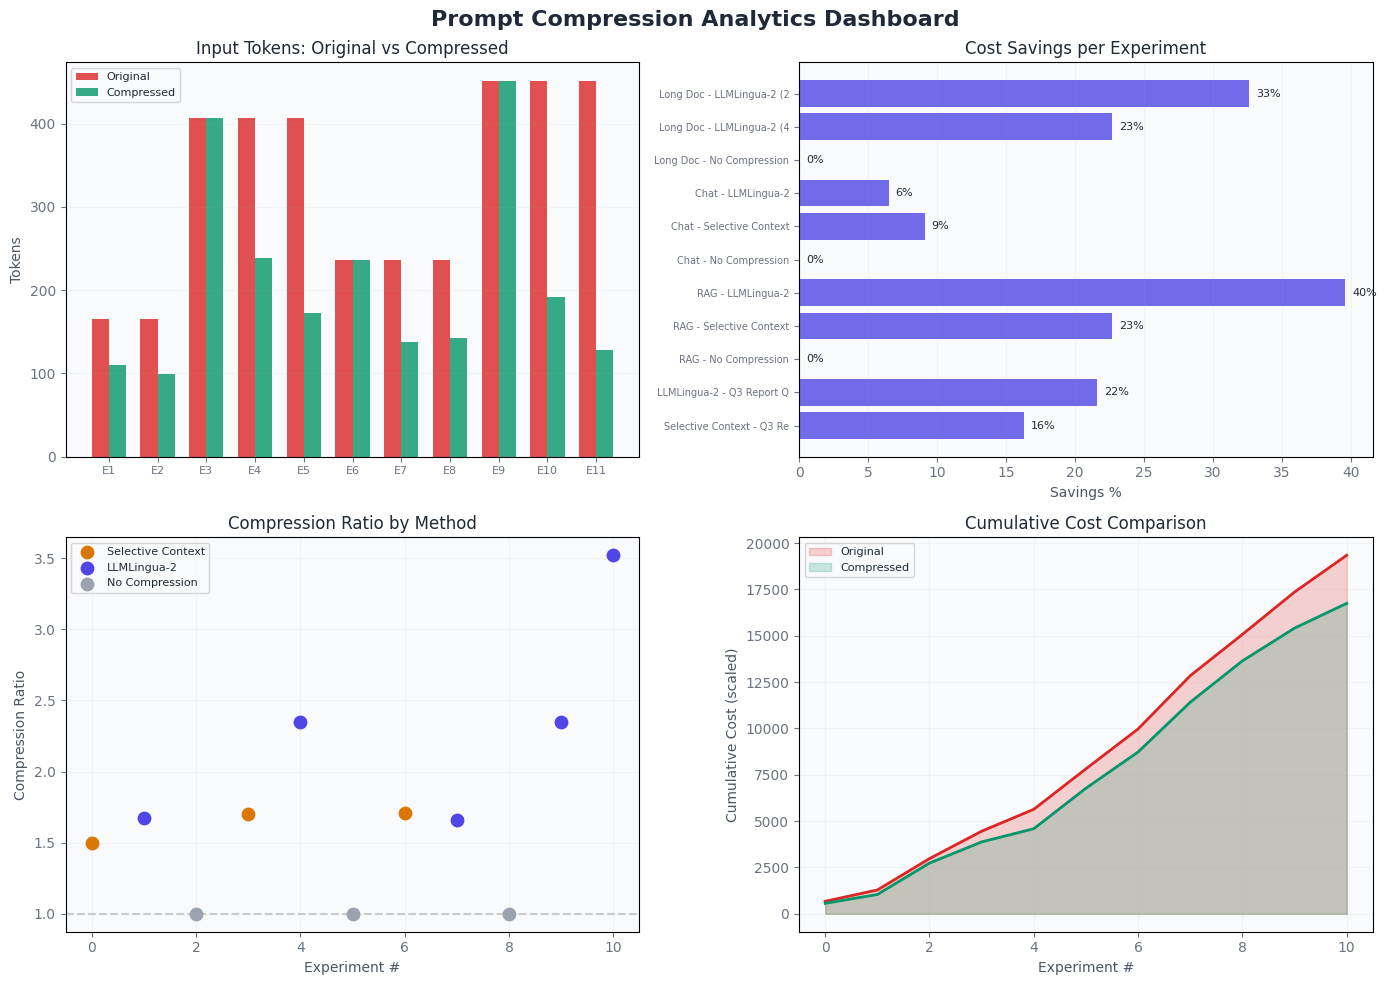

Dashboard saved to compression_dashboard.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({
    "figure.facecolor": "#ffffff", "axes.facecolor": "#f9fafb",
    "text.color": "#1f2937", "axes.labelcolor": "#4b5563",
    "xtick.color": "#6b7280", "ytick.color": "#6b7280",
})

df = tracker.summary_df()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Prompt Compression Analytics Dashboard", fontsize=16, fontweight="bold")

# 1 - Token comparison
ax = axes[0, 0]
x = range(len(df))
w = 0.35
ax.bar([i-w/2 for i in x], df["original_tokens"], w, label="Original", color="#dc2626", alpha=0.8)
ax.bar([i+w/2 for i in x], df["compressed_tokens"], w, label="Compressed", color="#059669", alpha=0.8)
ax.set_ylabel("Tokens"); ax.set_title("Input Tokens: Original vs Compressed")
ax.set_xticks(x); ax.set_xticklabels([f"E{i+1}" for i in x], fontsize=8)
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.1)

# 2 - Savings %
ax = axes[0, 1]
colors = ["#4f46e5" if m != "none" else "#9ca3af" for m in df["method"]]
bars = ax.barh(range(len(df)), df["savings_pct"], color=colors, alpha=0.8)
ax.set_xlabel("Savings %"); ax.set_title("Cost Savings per Experiment")
ax.set_yticks(range(len(df)))
ax.set_yticklabels(df["name"].str[:25], fontsize=7)
for b, p in zip(bars, df["savings_pct"]):
    ax.text(b.get_width()+0.5, b.get_y()+b.get_height()/2, f"{p:.0f}%", va="center", fontsize=8)
ax.grid(axis="x", alpha=0.1)

# 3 - Compression ratio scatter
ax = axes[1, 0]
for method, color, label in [("selective_context","#d97706","Selective Context"),
                              ("llmlingua2","#4f46e5","LLMLingua-2"),
                              ("none","#9ca3af","No Compression")]:
    sub = df[df["method"]==method]
    if not sub.empty:
        ax.scatter(sub.index, sub["compression_ratio"], c=color, s=80, label=label, zorder=5)
ax.set_ylabel("Compression Ratio"); ax.set_xlabel("Experiment #")
ax.set_title("Compression Ratio by Method")
ax.axhline(y=1, color="#9ca3af", linestyle="--", alpha=0.5)
ax.legend(fontsize=8); ax.grid(alpha=0.1)

# 4 - Cumulative cost
ax = axes[1, 1]
ax.fill_between(range(len(df)), df["original_cost"].cumsum()*1e6, alpha=0.2, color="#dc2626", label="Original")
ax.fill_between(range(len(df)), df["compressed_cost"].cumsum()*1e6, alpha=0.2, color="#059669", label="Compressed")
ax.plot(range(len(df)), df["original_cost"].cumsum()*1e6, color="#dc2626", lw=2)
ax.plot(range(len(df)), df["compressed_cost"].cumsum()*1e6, color="#059669", lw=2)
ax.set_ylabel("Cumulative Cost (scaled)"); ax.set_xlabel("Experiment #")
ax.set_title("Cumulative Cost Comparison"); ax.legend(fontsize=8); ax.grid(alpha=0.1)

plt.tight_layout()
plt.savefig("outputs/compression_dashboard.png", dpi=150, bbox_inches="tight", facecolor="#ffffff")
plt.show()
print("Dashboard saved to outputs/compression_dashboard.png")


### 10.3 Scale Projections

Using the average compression ratio from our experiments, project costs at production scale (10K–1M calls/month). These projections apply only to **input token costs** — output costs remain constant.

In [54]:
df = tracker.summary_df()
compressed = df[df["method"] != "none"]

if len(compressed) > 0:
    avg_pct = compressed["savings_pct"].mean()
    avg_ratio = compressed["compression_ratio"].mean()
    avg_orig = compressed["original_tokens"].mean()
    avg_comp = compressed["compressed_tokens"].mean()

    p_in = PRICING[LLM_MODEL]["input"]
    p_out = PRICING[LLM_MODEL]["output"]

    print("=" * 60)
    print("PRODUCTION SCALE PROJECTIONS")
    print("=" * 60)
    print(f"Based on {len(compressed)} experiments:")
    print(f"  Avg compression: {avg_ratio:.1f}x | Avg savings: {avg_pct:.1f}%")
    print()

    for calls in [10_000, 100_000, 500_000, 1_000_000]:
        avg_out = 200
        orig_cost = (calls * avg_orig * p_in + calls * avg_out * p_out) / 1e6
        comp_cost = (calls * avg_comp * p_in + calls * avg_out * p_out) / 1e6
        saved = orig_cost - comp_cost
        print(f"  {calls:>10,} calls/month:")
        print(f"    Without: ${orig_cost:>10,.2f}  |  With: ${comp_cost:>10,.2f}  |  Save: ${saved:>10,.2f}")


PRODUCTION SCALE PROJECTIONS
Based on 8 experiments:
  Avg compression: 2.1x | Avg savings: 21.4%

      10,000 calls/month:
    Without: $     22.30  |  With: $     19.05  |  Save: $      3.24
     100,000 calls/month:
    Without: $    222.95  |  With: $    190.53  |  Save: $     32.42
     500,000 calls/month:
    Without: $  1,114.75  |  With: $    952.62  |  Save: $    162.12
   1,000,000 calls/month:
    Without: $  2,229.50  |  With: $  1,905.25  |  Save: $    324.25


### 10.4 Export Results

In [ ]:
df = tracker.summary_df()
df.to_csv("compression_results.csv", index=False)
print(f"Exported {len(df)} experiments to compression_results.csv")
display(df[["name","method","original_tokens","compressed_tokens",
            "compression_ratio","savings_pct","original_cost","compressed_cost"]].round(6))


---
## 11. Where Compression Savings Are Most Significant

The table below summarizes where input compression delivers the **highest ROI** based on our experiments above. Use this to prioritize which parts of your pipeline to compress first.

### Impact Ranking (from our experiments)

| Rank | Use Case | Why Compression Helps Most |
|:----:|----------|---------------------------|
| 🥇 | **RAG Pipeline** | Retrieved docs are 60–80% of total input and full of redundancy. Every query pays this cost. |
| 🥈 | **Long Document QA** | Reports/papers have verbose prose — compression removes filler without losing facts. |
| 🥉 | **Multi-turn Chat** | History grows linearly with turns. Compressing older turns is safe and high-value. |
| 4 | **Few-shot Prompts** | Moderate savings, but consistent — same examples compressed once, reused many times. |
| 5 | **Code Context** | Lowest compression ratio (syntax is essential), but still worthwhile at scale. |

### When NOT to Compress

- **System prompts** — These are instructions, every word matters
- **User questions** — Short and precise, corruption breaks the task
- **Function/tool definitions** — JSON schemas cannot tolerate missing tokens
- **Inputs under 500 tokens** — Compression overhead (model inference) outweighs the savings
- **Safety-critical outputs** — Medical, legal, or financial tasks where every detail matters

In [45]:
# Show the actual compression impact from our experiments, grouped by use case
df = tracker.summary_df()
compressed_only = df[df["method"] != "none"].copy()

if len(compressed_only) > 0:
    print("INPUT TOKEN COMPRESSION — IMPACT BY USE CASE")
    print("=" * 75)
    print(f"{'Use Case':<35} {'Original':>8} {'Compressed':>10} {'Ratio':>7} {'Input Savings':>14}")
    print("-" * 75)
    for _, row in compressed_only.iterrows():
        print(f"{row['name']:<35} {row['original_tokens']:>8,} {row['compressed_tokens']:>10,} "
              f"{row['compression_ratio']:>6.1f}x {row['savings_pct']:>12.1f}%")
    print("-" * 75)
    print(f"{'AVERAGE':<35} {compressed_only['original_tokens'].mean():>8,.0f} "
          f"{compressed_only['compressed_tokens'].mean():>10,.0f} "
          f"{compressed_only['compression_ratio'].mean():>6.1f}x "
          f"{compressed_only['savings_pct'].mean():>12.1f}%")

    # Project the highest-impact scenario (RAG) at scale
    rag_rows = compressed_only[compressed_only["name"].str.contains("RAG")]
    if len(rag_rows) > 0:
        best_rag = rag_rows.loc[rag_rows["savings_pct"].idxmax()]
        print(f"\n💡 HIGHEST IMPACT: {best_rag['name']}")
        print(f"   At 100K calls/month with gpt-4.1 ($2.00/1M input tokens):")
        monthly_orig = 100_000 * best_rag["original_tokens"] * 2.00 / 1e6
        monthly_comp = 100_000 * best_rag["compressed_tokens"] * 2.00 / 1e6
        print(f"   Without compression: ${monthly_orig:,.2f}/month")
        print(f"   With compression:    ${monthly_comp:,.2f}/month")
        print(f"   Monthly savings:     ${monthly_orig - monthly_comp:,.2f}/month")
        print(f"   Annual savings:      ${(monthly_orig - monthly_comp) * 12:,.2f}/year")

INPUT TOKEN COMPRESSION — IMPACT BY USE CASE
Use Case                            Original Compressed   Ratio  Input Savings
---------------------------------------------------------------------------
Selective Context - Q3 Report QA         165        110    1.5x         16.3%
LLMLingua-2 - Q3 Report QA               165         99    1.7x         22.2%
RAG - Selective Context                  407        239    1.7x         22.1%
RAG - LLMLingua-2                        407        173    2.4x         33.1%
Chat - Selective Context                 236        138    1.7x         10.2%
Chat - LLMLingua-2                       236        142    1.7x          6.5%
Long Doc - LLMLingua-2 (40%)             451        192    2.4x         20.3%
Long Doc - LLMLingua-2 (25%)             451        128    3.5x         41.0%
Few-Shot - LLMLingua-2                   183        120    1.5x         33.0%
Code - LLMLingua-2                       398        231    1.7x         14.6%
--------------------

---
## Bonus: Test Your Own Text

Paste any text and see how both methods compress it. Works best with **500+ tokens** — shorter texts won't show meaningful compression.

In [46]:
YOUR_TEXT = """
PASTE YOUR OWN LONG TEXT HERE.
This could be a document, conversation history, retrieved context,
or any prompt content you want to compress.
"""

YOUR_QUESTION = "What is the main point?"

print("YOUR CUSTOM COMPRESSION TEST")
print("=" * 60)

orig = count_tokens(YOUR_TEXT)
print(f"Original: {orig} tokens\n")

# Selective Context
t0 = time.time()
sc_out, _ = sc(YOUR_TEXT, reduce_ratio=0.5)
sc_ms = (time.time() - t0) * 1000
sc_tok = count_tokens(sc_out)
print(f"Selective Context: {sc_tok} tokens ({sc_ms:.0f}ms) - {(1-sc_tok/orig)*100:.0f}% reduction")

# LLMLingua-2
t0 = time.time()
ll2_out = llm_lingua.compress_prompt(YOUR_TEXT, question=YOUR_QUESTION, rate=0.5,
                                      force_tokens=["\n", ".", "?", "!"])
ll2_ms = (time.time() - t0) * 1000
ll2_tok = count_tokens(ll2_out["compressed_prompt"])
print(f"LLMLingua-2:       {ll2_tok} tokens ({ll2_ms:.0f}ms) - {(1-ll2_tok/orig)*100:.0f}% reduction")

print(f"\n--- Selective Context ---\n{sc_out.strip()[:500]}")
print(f"\n--- LLMLingua-2 ---\n{ll2_out['compressed_prompt'].strip()[:500]}")


YOUR CUSTOM COMPRESSION TEST
Original: 30 tokens

Selective Context: 19 tokens (927ms) - 37% reduction
LLMLingua-2:       15 tokens (2460ms) - 50% reduction

--- Selective Context ---
PASTE YOUR OWN LONG TEXT HERE This could a document conversation history retrieved context any prompt content compress

--- LLMLingua-2 ---
PASTE LONG TEXT.
 document conversation history retrieved context
 content compress.


---

## Quick Reference

### What Prompt Compression Is (and Isn't)

| | ✅ What it does | ❌ What it doesn't do |
|---|---|---|
| **Scope** | Reduces **input** tokens sent to the LLM | Does NOT reduce output tokens (use `max_tokens` for that) |
| **Mechanism** | Removes redundant/predictable tokens from context | Does NOT change the system prompt or user question |
| **Cost impact** | Saves on **input pricing** only | Output cost stays the same regardless of compression |
| **Quality** | Preserves key information at moderate ratios (2–3x) | May lose nuance at aggressive ratios (>4x) |

### When to Use What

| Scenario | Best Method | Expected Savings | Notes |
|----------|------------|------------------:|-------|
| Quick prototype, < 2x compression needed | **Selective Context** | 20–40% | Simplest setup, GPT-2 only |
| **Production RAG pipeline** | **LLMLingua-2** | **40–70%** | **Highest ROI — do this first** |
| Multi-turn chat history | **LLMLingua-2** | 30–50% | Preserves conversation structure |
| Long document QA | **LLMLingua-2** | 50–75% | Reports are full of compressible filler |
| Few-shot examples | **Either** | 30–50% | Protect labels with `force_tokens` |
| Code context | **LLMLingua-2** + `force_tokens` | 20–40% | Protect syntax characters |
| **Short queries (< 500 tokens)** | **Skip compression** | **~0%** | **Overhead isn't worth it** |

### Five Rules for Production

1. **Only compress the context** — never the system prompt, user question, or function definitions
2. **Use `force_tokens`** — always protect `\n`, `.`, `?`, `!` (and `()=:_` for code)
3. **Benchmark on YOUR data** — if quality drops > 5%, reduce compression ratio
4. **Layer with caching** — compress first, then cache the compressed prompt (saves compute + tokens)
5. **Measure savings at scale** — a 40% input reduction at 500K calls/month = real money

---
*Prompt Compression Masterclass — Input Token Optimization for LLM Pipelines*

---
## 12. Using LLMLingua-2 in Production — Can You? Should You?

**Short answer: Yes.** LLMLingua-2 is production-viable and already used in real systems. But there are specific concerns to address.

### Production Architecture

```
┌────────────────────────────────────────────────────────────────────────┐
│                    Production RAG Pipeline                             │
│                                                                        │
│  User Query ──► Retriever ──► [5 chunks, ~4000 tokens]                │
│                                       │                                │
│                                       ▼                                │
│                          ┌─────────────────────┐                       │
│                          │  Compression Service │  ◄── LLMLingua-2     │
│                          │  (XLM-RoBERTa, CPU) │      ~50-200ms       │
│                          └──────────┬──────────┘                       │
│                                     │                                  │
│                                     ▼                                  │
│                          [~1600 tokens, 60% saved]                     │
│                                     │                                  │
│                  System Prompt + Compressed Context + Question          │
│                                     │                                  │
│                                     ▼                                  │
│                               ┌──────────┐                             │
│                               │  LLM API │  ◄── 60% cheaper input     │
│                               └──────────┘                             │
│                                     │                                  │
│                                     ▼                                  │
│                               [LLM Response]                           │
└────────────────────────────────────────────────────────────────────────┘
```

### Key Production Concerns and Solutions

| Concern | Detail | Solution |
|---------|--------|----------|
| **Latency** | XLM-RoBERTa inference adds 50-200ms per request | Acceptable — LLM call itself takes 500-3000ms. Compression is less than 10% overhead |
| **Model size** | ~1.2GB in memory | Load once at startup, share across requests via singleton |
| **Concurrency** | PyTorch models are not thread-safe by default | Use `torch.no_grad()` + thread locks, or run multiple worker processes |
| **GPU vs CPU** | GPU is faster but not always available | CPU works fine for under 10K tokens. Use GPU for batch processing or more than 50 req/s |
| **Scaling** | Single instance handles ~50-100 req/s on CPU | Horizontal scaling: run N compression workers behind a load balancer |
| **Failures** | Model loading or inference can fail | Fallback to uncompressed prompt — never block the request |
| **Caching** | Same context compressed repeatedly | Cache compressed outputs keyed by (text_hash, rate, force_tokens) |
| **Quality degradation** | Over-compression loses meaning | Set rate >= 0.4 in production. Monitor LLM response quality metrics |
| **Token counting** | Need accurate counts for cost tracking | Use `tiktoken` — it matches OpenAI's exact tokenizer |

### When to Deploy Compression (Decision Framework)

```
Is your avg input > 1000 tokens?
  ├─ NO  → Skip compression (overhead > savings)
  └─ YES → Is your monthly LLM spend > $500?
              ├─ NO  → Optional — savings are small in absolute $
              └─ YES → Is latency-critical (< 200ms total)?
                          ├─ YES → Pre-compress at indexing time (offline)
                          └─ NO  → Deploy real-time compression
```

### Deployment Options

| Option | How | Best For |
|--------|-----|----------|
| **In-process module** | Import `PromptCompressionService` in your app | Monoliths, simple services |
| **Sidecar service** | Separate FastAPI container, same pod | Microservices, Kubernetes |
| **Shared compression service** | Central API all services call | Multiple consumers, team-wide |
| **Offline pre-compression** | Compress at indexing/ingestion time | RAG with static documents |

---
## 13. Production Utility Class — `PromptCompressionService`

A drop-in module you can copy into any project. Features:

| Feature | What it does |
|---------|-------------|
| **Singleton model loading** | Loads XLM-RoBERTa once, reuses across all calls |
| **Thread-safe** | Uses `threading.Lock` so concurrent requests don't corrupt model state |
| **Built-in caching** | LRU cache avoids re-compressing identical text (configurable size) |
| **Auto fallback** | If compression fails, returns original text instead of crashing |
| **Token counting** | Returns token counts and savings metrics with every result |
| **Min-token guard** | Skips compression for short inputs (configurable threshold) |
| **Batch support** | Compress multiple texts in one call |

### Usage as a module

```python
# In your project:
from prompt_compression_service import PromptCompressionService

svc = PromptCompressionService(model_path="./models/llmlingua-2-xlm-roberta-large-meetingbank")

result = svc.compress(
    text="your long context here...",
    question="what is the summary?",
    rate=0.5,
)
print(result["compressed_text"])    # compressed output
print(result["savings_pct"])        # e.g. 48.2
```

In [ ]:
import threading
import hashlib
import time
from collections import OrderedDict
from dataclasses import dataclass, field
from typing import Optional

import tiktoken
from llmlingua import PromptCompressor


@dataclass
class CompressionResult:
    """Result of a single compression operation."""
    compressed_text: str
    original_tokens: int
    compressed_tokens: int
    compression_ratio: float
    savings_pct: float
    compression_time_ms: float
    from_cache: bool = False
    skipped: bool = False  # True if input was below min_tokens threshold


class PromptCompressionService:
    """
    Production-ready prompt compression using LLMLingua-2.

    Features:
    - Thread-safe singleton model loading
    - LRU caching of compressed results
    - Auto fallback on failure (returns original text)
    - Min-token guard to skip short inputs
    - Batch compression support

    Usage:
        svc = PromptCompressionService(model_path="./models/llmlingua-2-xlm-roberta-large-meetingbank")
        result = svc.compress("long text here...", rate=0.5)
        print(result.compressed_text, result.savings_pct)
    """

    def __init__(
        self,
        model_path: str,
        device: str = "cpu",
        default_rate: float = 0.5,
        default_force_tokens: Optional[list] = None,
        min_tokens: int = 100,
        cache_size: int = 512,
        tiktoken_model: str = "gpt-4o",
    ):
        self._model_path = model_path
        self._device = device
        self.default_rate = default_rate
        self.default_force_tokens = default_force_tokens or ["\n", ".", "!", "?"]
        self.min_tokens = min_tokens
        self._cache_size = cache_size

        # Token counter
        try:
            self._enc = tiktoken.encoding_for_model(tiktoken_model)
        except KeyError:
            self._enc = tiktoken.get_encoding("cl100k_base")

        # Thread safety
        self._lock = threading.Lock()

        # LRU cache: OrderedDict acts as LRU when we move accessed keys to end
        self._cache: OrderedDict[str, CompressionResult] = OrderedDict()

        # Lazy-load model on first call (avoids slow import-time loading)
        self._compressor: Optional[PromptCompressor] = None

        # Metrics
        self.total_calls = 0
        self.cache_hits = 0
        self.total_tokens_saved = 0

    def _ensure_model(self):
        """Load the model if not already loaded (called under lock)."""
        if self._compressor is None:
            self._compressor = PromptCompressor(
                model_name=self._model_path,
                use_llmlingua2=True,
                device_map=self._device,
            )

    def _count_tokens(self, text: str) -> int:
        return len(self._enc.encode(text))

    def _cache_key(self, text: str, question: Optional[str], rate: float,
                   force_tokens: tuple) -> str:
        """Generate a deterministic cache key."""
        raw = f"{text}|{question or ''}|{rate}|{force_tokens}"
        return hashlib.sha256(raw.encode()).hexdigest()

    def _evict_cache(self):
        """Remove oldest entries if cache exceeds max size."""
        while len(self._cache) > self._cache_size:
            self._cache.popitem(last=False)

    def compress(
        self,
        text: str,
        question: Optional[str] = None,
        rate: Optional[float] = None,
        force_tokens: Optional[list] = None,
    ) -> CompressionResult:
        """
        Compress a single text. Thread-safe with caching and fallback.

        Args:
            text: The context/document to compress (NOT the question/instruction).
            question: Optional question for question-aware compression.
            rate: Token retention rate (0.0-1.0). Default: self.default_rate.
            force_tokens: Tokens to never remove. Default: self.default_force_tokens.

        Returns:
            CompressionResult with compressed text and metrics.
        """
        self.total_calls += 1
        rate = rate or self.default_rate
        ft = tuple(force_tokens or self.default_force_tokens)

        orig_tokens = self._count_tokens(text)

        # Skip compression for short inputs
        if orig_tokens < self.min_tokens:
            return CompressionResult(
                compressed_text=text,
                original_tokens=orig_tokens,
                compressed_tokens=orig_tokens,
                compression_ratio=1.0,
                savings_pct=0.0,
                compression_time_ms=0.0,
                skipped=True,
            )

        # Check cache
        key = self._cache_key(text, question, rate, ft)
        if key in self._cache:
            self.cache_hits += 1
            result = self._cache[key]
            self._cache.move_to_end(key)  # Mark as recently used
            return CompressionResult(
                compressed_text=result.compressed_text,
                original_tokens=result.original_tokens,
                compressed_tokens=result.compressed_tokens,
                compression_ratio=result.compression_ratio,
                savings_pct=result.savings_pct,
                compression_time_ms=result.compression_time_ms,
                from_cache=True,
            )

        # Compress under lock (PyTorch model is not thread-safe)
        with self._lock:
            self._ensure_model()
            try:
                t0 = time.time()
                kwargs = {"rate": rate, "force_tokens": list(ft)}
                if question:
                    kwargs["question"] = question
                ll2_result = self._compressor.compress_prompt(text, **kwargs)
                elapsed_ms = (time.time() - t0) * 1000
            except Exception as e:
                # FALLBACK: return original text on any compression failure
                print(f"[PromptCompressionService] Compression failed, returning original: {e}")
                return CompressionResult(
                    compressed_text=text,
                    original_tokens=orig_tokens,
                    compressed_tokens=orig_tokens,
                    compression_ratio=1.0,
                    savings_pct=0.0,
                    compression_time_ms=0.0,
                )

        compressed_text = ll2_result["compressed_prompt"]
        comp_tokens = self._count_tokens(compressed_text)
        ratio = orig_tokens / max(comp_tokens, 1)
        savings = (1 - comp_tokens / orig_tokens) * 100 if orig_tokens > 0 else 0.0

        self.total_tokens_saved += (orig_tokens - comp_tokens)

        result = CompressionResult(
            compressed_text=compressed_text,
            original_tokens=orig_tokens,
            compressed_tokens=comp_tokens,
            compression_ratio=round(ratio, 2),
            savings_pct=round(savings, 1),
            compression_time_ms=round(elapsed_ms, 1),
        )

        # Store in cache
        self._cache[key] = result
        self._evict_cache()

        return result

    def compress_batch(
        self,
        texts: list[str],
        question: Optional[str] = None,
        rate: Optional[float] = None,
        force_tokens: Optional[list] = None,
    ) -> list[CompressionResult]:
        """Compress multiple texts. Each is compressed independently."""
        return [self.compress(t, question, rate, force_tokens) for t in texts]

    def build_prompt(
        self,
        instruction: str,
        context: str,
        question: str,
        rate: Optional[float] = None,
        force_tokens: Optional[list] = None,
    ) -> tuple[str, CompressionResult]:
        """
        Compress context and assemble a full prompt (instruction + compressed context + question).
        Returns (prompt_string, compression_result).
        """
        result = self.compress(context, question=question, rate=rate, force_tokens=force_tokens)

        prompt = f"""{instruction}

{result.compressed_text}

Question: {question}
Answer:"""
        return prompt, result

    def stats(self) -> dict:
        """Return service-level metrics."""
        return {
            "total_calls": self.total_calls,
            "cache_hits": self.cache_hits,
            "cache_hit_rate": f"{self.cache_hits / max(self.total_calls, 1) * 100:.1f}%",
            "total_tokens_saved": self.total_tokens_saved,
            "cache_entries": len(self._cache),
            "model_loaded": self._compressor is not None,
        }


print("PromptCompressionService class defined")
print("Features: thread-safe, cached, auto-fallback, batch support")

### 13.1 Usage Examples

Test the service with the same sample text from our earlier experiments. Notice:
- First call loads the model (slow) — subsequent calls are fast
- Second identical call returns from cache (0ms compression time)
- Short text is auto-skipped

In [ ]:
# Initialize the service (model loads lazily on first compress call)
svc = PromptCompressionService(
    model_path=llmlingua_path,   # reuse the model path from earlier
    device="cpu",
    default_rate=0.5,
    min_tokens=100,
    cache_size=256,
)
print("Service created (model will load on first call)\n")

# --- Example 1: Basic compression ---
print("=" * 60)
print("EXAMPLE 1: Basic compression")
print("=" * 60)
r1 = svc.compress(sample_text, question="What drove revenue growth?")
print(f"  Original:   {r1.original_tokens} tokens")
print(f"  Compressed: {r1.compressed_tokens} tokens")
print(f"  Ratio:      {r1.compression_ratio}x")
print(f"  Savings:    {r1.savings_pct}%")
print(f"  Time:       {r1.compression_time_ms:.0f}ms")
print(f"  From cache: {r1.from_cache}")
print(f"  Output:     {r1.compressed_text[:150]}...")

# --- Example 2: Cache hit (same input) ---
print(f"\n{'=' * 60}")
print("EXAMPLE 2: Same call again — should be cached")
print("=" * 60)
r2 = svc.compress(sample_text, question="What drove revenue growth?")
print(f"  From cache: {r2.from_cache}")
print(f"  Time:       {r2.compression_time_ms:.0f}ms (original compression time, served from cache)")

# --- Example 3: Short text auto-skip ---
print(f"\n{'=' * 60}")
print("EXAMPLE 3: Short text — auto-skipped")
print("=" * 60)
r3 = svc.compress("This is a short query about AI.", question="What is AI?")
print(f"  Skipped:    {r3.skipped}")
print(f"  Tokens:     {r3.original_tokens} (below min_tokens={svc.min_tokens})")

# --- Example 4: build_prompt helper ---
print(f"\n{'=' * 60}")
print("EXAMPLE 4: build_prompt — full prompt assembly")
print("=" * 60)
prompt, r4 = svc.build_prompt(
    instruction="Answer the question based on the report below.",
    context=sample_text,
    question="What was the revenue?",
    rate=0.4,
)
print(f"  Full prompt length: {len(prompt)} chars")
print(f"  Context savings:    {r4.savings_pct}%")
print(f"  Prompt preview:\n{prompt[:300]}...")

# --- Example 5: Batch compression ---
print(f"\n{'=' * 60}")
print("EXAMPLE 5: Batch compression (RAG chunks)")
print("=" * 60)
results = svc.compress_batch(
    retrieved_docs,  # 4 RAG chunks from Section 4
    question="How does semantic caching work?",
    rate=0.5,
)
for i, r in enumerate(results):
    status = "skipped" if r.skipped else f"{r.savings_pct}% saved"
    print(f"  Chunk {i+1}: {r.original_tokens} → {r.compressed_tokens} tokens ({status})")

# --- Service stats ---
print(f"\n{'=' * 60}")
print("SERVICE STATS")
print("=" * 60)
for k, v in svc.stats().items():
    print(f"  {k}: {v}")

---
## 14. REST API — FastAPI Server

Deploy compression as an HTTP service that any application can call. The code below is a **complete, runnable FastAPI server** you can save as `compression_server.py` and run with `uvicorn`.

### API Endpoints

| Method | Endpoint | Purpose |
|--------|----------|---------|
| `POST` | `/compress` | Compress a single text |
| `POST` | `/compress/batch` | Compress multiple texts |
| `POST` | `/build-prompt` | Compress context + assemble full prompt |
| `GET` | `/health` | Health check — confirms model is loaded |
| `GET` | `/stats` | Service metrics (calls, cache hits, tokens saved) |

### Request/Response Example

```bash
curl -X POST http://localhost:8000/compress \
  -H "Content-Type: application/json" \
  -d '{
    "text": "The quarterly financial report indicates...",
    "question": "What was the revenue?",
    "rate": 0.5
  }'
```

```json
{
  "compressed_text": "quarterly financial report revenue...",
  "original_tokens": 156,
  "compressed_tokens": 78,
  "compression_ratio": 2.0,
  "savings_pct": 50.0,
  "compression_time_ms": 87.3,
  "from_cache": false,
  "skipped": false
}
```

In [ ]:
# ============================================================
# compression_server.py — Save this file and run with:
#   pip install fastapi uvicorn
#   uvicorn compression_server:app --host 0.0.0.0 --port 8000
# ============================================================

COMPRESSION_SERVER_CODE = '''
"""
Prompt Compression REST API Server
Run: uvicorn compression_server:app --host 0.0.0.0 --port 8000 --workers 1
Note: Use --workers 1 because the PyTorch model shares memory.
      For higher throughput, use multiple single-worker containers behind a load balancer.
"""

import os
import time
import hashlib
import threading
from collections import OrderedDict
from typing import Optional

import tiktoken
from pydantic import BaseModel, Field
from fastapi import FastAPI, HTTPException
from llmlingua import PromptCompressor


# ── Pydantic models for request/response ──────────────────────

class CompressRequest(BaseModel):
    text: str = Field(..., min_length=1, description="Text to compress")
    question: Optional[str] = Field(None, description="Question for question-aware compression")
    rate: float = Field(0.5, ge=0.1, le=1.0, description="Token retention rate (0.1 to 1.0)")
    force_tokens: list[str] = Field(
        default=["\\n", ".", "!", "?"],
        description="Tokens to never remove"
    )

class BatchCompressRequest(BaseModel):
    texts: list[str] = Field(..., min_length=1, max_length=50, description="Texts to compress")
    question: Optional[str] = None
    rate: float = Field(0.5, ge=0.1, le=1.0)
    force_tokens: list[str] = Field(default=["\\n", ".", "!", "?"])

class BuildPromptRequest(BaseModel):
    instruction: str = Field(..., description="Instruction/system prompt (not compressed)")
    context: str = Field(..., description="Context to compress")
    question: str = Field(..., description="Question (not compressed)")
    rate: float = Field(0.5, ge=0.1, le=1.0)
    force_tokens: list[str] = Field(default=["\\n", ".", "!", "?"])

class CompressResponse(BaseModel):
    compressed_text: str
    original_tokens: int
    compressed_tokens: int
    compression_ratio: float
    savings_pct: float
    compression_time_ms: float
    from_cache: bool
    skipped: bool

class PromptResponse(BaseModel):
    prompt: str
    compression: CompressResponse


# ── Application ───────────────────────────────────────────────

app = FastAPI(
    title="Prompt Compression API",
    description="LLMLingua-2 prompt compression as a REST service",
    version="1.0.0",
)

# Globals (initialized on startup)
_compressor = None
_lock = threading.Lock()
_cache: OrderedDict = OrderedDict()
_enc = None
_stats = {"total_calls": 0, "cache_hits": 0, "total_tokens_saved": 0}

MODEL_PATH = os.getenv("MODEL_PATH", "./models/llmlingua-2-xlm-roberta-large-meetingbank")
DEVICE = os.getenv("DEVICE", "cpu")
CACHE_SIZE = int(os.getenv("CACHE_SIZE", "512"))
MIN_TOKENS = int(os.getenv("MIN_TOKENS", "100"))


@app.on_event("startup")
def load_model():
    """Load the compression model at server startup."""
    global _compressor, _enc
    print(f"Loading LLMLingua-2 from {MODEL_PATH} on {DEVICE}...")
    _compressor = PromptCompressor(
        model_name=MODEL_PATH,
        use_llmlingua2=True,
        device_map=DEVICE,
    )
    try:
        _enc = tiktoken.encoding_for_model("gpt-4o")
    except KeyError:
        _enc = tiktoken.get_encoding("cl100k_base")
    print("Model loaded and ready.")


def _count_tokens(text: str) -> int:
    return len(_enc.encode(text))


def _cache_key(text: str, question: Optional[str], rate: float, force_tokens: list) -> str:
    raw = f"{text}|{question or ''}|{rate}|{tuple(force_tokens)}"
    return hashlib.sha256(raw.encode()).hexdigest()


def _do_compress(text: str, question: Optional[str], rate: float,
                 force_tokens: list) -> CompressResponse:
    _stats["total_calls"] += 1
    orig_tokens = _count_tokens(text)

    # Skip short inputs
    if orig_tokens < MIN_TOKENS:
        return CompressResponse(
            compressed_text=text, original_tokens=orig_tokens,
            compressed_tokens=orig_tokens, compression_ratio=1.0,
            savings_pct=0.0, compression_time_ms=0.0,
            from_cache=False, skipped=True,
        )

    # Check cache
    key = _cache_key(text, question, rate, force_tokens)
    if key in _cache:
        _stats["cache_hits"] += 1
        cached = _cache[key]
        _cache.move_to_end(key)
        return CompressResponse(**{**cached, "from_cache": True})

    # Compress under lock
    with _lock:
        try:
            t0 = time.time()
            kwargs = {"rate": rate, "force_tokens": force_tokens}
            if question:
                kwargs["question"] = question
            result = _compressor.compress_prompt(text, **kwargs)
            elapsed = (time.time() - t0) * 1000
        except Exception as e:
            raise HTTPException(status_code=500, detail=f"Compression failed: {str(e)}")

    comp_text = result["compressed_prompt"]
    comp_tokens = _count_tokens(comp_text)
    ratio = orig_tokens / max(comp_tokens, 1)
    savings = (1 - comp_tokens / orig_tokens) * 100

    _stats["total_tokens_saved"] += (orig_tokens - comp_tokens)

    resp_data = {
        "compressed_text": comp_text,
        "original_tokens": orig_tokens,
        "compressed_tokens": comp_tokens,
        "compression_ratio": round(ratio, 2),
        "savings_pct": round(savings, 1),
        "compression_time_ms": round(elapsed, 1),
        "from_cache": False,
        "skipped": False,
    }

    # Cache the result
    _cache[key] = resp_data
    while len(_cache) > CACHE_SIZE:
        _cache.popitem(last=False)

    return CompressResponse(**resp_data)


# ── Endpoints ─────────────────────────────────────────────────

@app.post("/compress", response_model=CompressResponse)
def compress(req: CompressRequest):
    """Compress a single text."""
    return _do_compress(req.text, req.question, req.rate, req.force_tokens)


@app.post("/compress/batch", response_model=list[CompressResponse])
def compress_batch(req: BatchCompressRequest):
    """Compress multiple texts."""
    return [_do_compress(t, req.question, req.rate, req.force_tokens) for t in req.texts]


@app.post("/build-prompt", response_model=PromptResponse)
def build_prompt(req: BuildPromptRequest):
    """Compress context and assemble a full prompt."""
    compression = _do_compress(req.context, req.question, req.rate, req.force_tokens)
    prompt = f"""{req.instruction}

{compression.compressed_text}

Question: {req.question}
Answer:"""
    return PromptResponse(prompt=prompt, compression=compression)


@app.get("/health")
def health():
    """Health check."""
    return {
        "status": "healthy" if _compressor is not None else "model_not_loaded",
        "model_path": MODEL_PATH,
        "device": DEVICE,
    }


@app.get("/stats")
def stats():
    """Service metrics."""
    return {
        **_stats,
        "cache_entries": len(_cache),
        "cache_hit_rate": f"{_stats['cache_hits'] / max(_stats['total_calls'], 1) * 100:.1f}%",
    }
'''

# Write the server file to disk
server_path = os.path.join(os.getcwd(), "compression_server.py")
with open(server_path, "w") as f:
    f.write(COMPRESSION_SERVER_CODE.strip())

print(f"Server written to: {server_path}")
print()
print("To run the server:")
print("  pip install fastapi uvicorn")
print("  uvicorn compression_server:app --host 0.0.0.0 --port 8000")
print()
print("Then test with:")
print('  curl -X POST http://localhost:8000/compress \\')
print('    -H "Content-Type: application/json" \\')
print('    -d \'{"text": "your long text...", "rate": 0.5}\'')

### 14.1 Python Client for the REST API

Use this lightweight client in any Python service to call the compression server. No model dependencies needed — just `requests`.

```python
# compression_client.py — drop into any project
import requests

class CompressionClient:
    def __init__(self, base_url="http://localhost:8000"):
        self.base_url = base_url.rstrip("/")

    def compress(self, text, question=None, rate=0.5):
        resp = requests.post(f"{self.base_url}/compress", json={
            "text": text, "question": question, "rate": rate,
        })
        resp.raise_for_status()
        return resp.json()

    def build_prompt(self, instruction, context, question, rate=0.5):
        resp = requests.post(f"{self.base_url}/build-prompt", json={
            "instruction": instruction, "context": context,
            "question": question, "rate": rate,
        })
        resp.raise_for_status()
        return resp.json()

# Usage:
# client = CompressionClient("http://compression-svc:8000")
# result = client.compress(rag_context, question="How does caching work?", rate=0.4)
# compressed = result["compressed_text"]
```

### 14.2 Docker Deployment

```dockerfile
# Dockerfile
FROM python:3.11-slim

WORKDIR /app
RUN pip install --no-cache-dir fastapi uvicorn llmlingua tiktoken torch transformers

# Copy model and server
COPY models/llmlingua-2-xlm-roberta-large-meetingbank /app/models/llmlingua-2
COPY compression_server.py /app/

ENV MODEL_PATH=/app/models/llmlingua-2
ENV DEVICE=cpu
ENV CACHE_SIZE=1024
ENV MIN_TOKENS=100

EXPOSE 8000
CMD ["uvicorn", "compression_server:app", "--host", "0.0.0.0", "--port", "8000", "--workers", "1"]
```

```yaml
# docker-compose.yml
services:
  compression:
    build: .
    ports:
      - "8000:8000"
    environment:
      - MODEL_PATH=/app/models/llmlingua-2
      - DEVICE=cpu
      - CACHE_SIZE=1024
    deploy:
      resources:
        limits:
          memory: 3G    # Model needs ~1.5GB, leave headroom
    healthcheck:
      test: ["CMD", "curl", "-f", "http://localhost:8000/health"]
      interval: 30s
      retries: 3
```

### 14.3 Integration Patterns

**Pattern A: Inline in your RAG pipeline (module import)**
```python
from prompt_compression_service import PromptCompressionService

svc = PromptCompressionService(model_path="./models/llmlingua-2")

def rag_pipeline(query: str, retrieved_docs: list[str]) -> str:
    context = "\n\n".join(retrieved_docs)
    prompt, stats = svc.build_prompt(
        instruction="Answer using the context below.",
        context=context,
        question=query,
        rate=0.4,
    )
    response = call_llm(prompt)
    return response
```

**Pattern B: Sidecar REST service (microservices)**
```python
from compression_client import CompressionClient

client = CompressionClient("http://compression-svc:8000")

def rag_pipeline(query: str, retrieved_docs: list[str]) -> str:
    context = "\n\n".join(retrieved_docs)
    result = client.build_prompt(
        instruction="Answer using the context below.",
        context=context,
        question=query,
        rate=0.4,
    )
    response = call_llm(result["prompt"])
    return response
```

**Pattern C: Offline pre-compression at indexing time**
```python
# At document indexing time (not query time):
for chunk in document_chunks:
    compressed = svc.compress(chunk.text, rate=0.4)
    vector_db.upsert(
        id=chunk.id,
        embedding=embed(chunk.text),         # embed ORIGINAL (better retrieval)
        metadata={
            "original_text": chunk.text,
            "compressed_text": compressed.compressed_text,  # store compressed
        }
    )

# At query time — zero compression latency:
results = vector_db.search(query_embedding, top_k=5)
context = "\n\n".join(r.metadata["compressed_text"] for r in results)
```